In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_test.csv
/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_train.csv


In [2]:
import pandas as pd

train_path = "/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_train.csv"
test_path = "/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_test.csv"

train = pd.read_csv(train_path, sep=None, engine="python")
test = pd.read_csv(test_path, sep=None, engine="python")

print("TRAIN SHAPE:", train.shape)
print("TEST SHAPE:", test.shape)

print("\nTRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTRAIN DATA TYPES:")
print(train.dtypes)

print("\nFIRST 5 TRAIN ROWS:")
display(train.head())

print("\nFIRST 5 TEST ROWS:")
display(test.head())

TRAIN SHAPE: (36904, 14)
TEST SHAPE: (9158, 13)

TRAIN COLUMNS:
['Time', 'CellName', 'PRBUsageUL', 'PRBUsageDL', 'meanThr_DL', 'meanThr_UL', 'maxThr_DL', 'maxThr_UL', 'meanUE_DL', 'meanUE_UL', 'maxUE_DL', 'maxUE_UL', 'maxUE_UL+DL', 'Unusual']

TRAIN DATA TYPES:
Time            object
CellName        object
PRBUsageUL     float64
PRBUsageDL     float64
meanThr_DL     float64
meanThr_UL     float64
maxThr_DL      float64
maxThr_UL      float64
meanUE_DL      float64
meanUE_UL      float64
maxUE_DL         int64
maxUE_UL         int64
maxUE_UL+DL      int64
Unusual          int64
dtype: object

FIRST 5 TRAIN ROWS:


,Time,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
0,10:45,3BLTE,12.3848,1.4019,0.3927,0.0438,16.6522,0.6806,1.1293,1.0491,5,3,8,1
1,9:45,1BLTE,22.0438,2.0016,0.5620,0.2697,10.3994,1.1771,1.4480,1.1630,6,5,11,1
2,7:45,9BLTE,0.5105,0.4258,0.0152,0.0106,0.2755,0.1685,1.0379,1.0535,1,2,3,1
3,2:45,4ALTE,1.9963,1.1513,0.9908,0.0245,64.7465,0.8747,1.0766,1.0526,3,2,5,1
4,3:30,10BLTE,0.3030,0.4040,0.0160,0.0130,0.3480,0.1680,1.0110,1.0110,2,1,3,0



FIRST 5 TEST ROWS:


,Time,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL
0,3:00,6ALTE,3.8177,1.5251,0.5829,0.0445,23.1688,0.7669,1.0262,0.0100,3,3,6
1,20:30,6ULTE,2.0210,3.3350,0.5690,0.0750,29.2650,1.0490,1.3140,0.0100,6,3,9
2,11:30,2ALTE,0.5050,0.4040,0.0140,0.0100,0.2270,0.0970,1.0110,0.0100,2,1,3
3,6:45,3CLTE,1.0110,0.5050,0.2380,0.0210,20.9620,0.6090,1.0110,1.0110,2,1,3
4,15:45,6CLTE,4.0269,0.5104,0.0807,0.0414,3.9317,1.7811,1.0575,0.0107,3,2,5


In [3]:
# 1. Data types
print("DATA TYPES")
display(train.dtypes.to_frame("dtype"))

# 2. Missing values
print("\nMISSING VALUES")
missing = pd.DataFrame({
    "Train Missing": train.isnull().sum(),
    "Train Missing %": (train.isnull().mean() * 100).round(2),
    "Test Missing": test.isnull().sum() if set(test.columns) == set(train.columns) else [
        test[c].isnull().sum() if c in test.columns else None
        for c in train.columns
    ]
})
display(missing)

# 3. Duplicate rows
print("\nDUPLICATE ROWS")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())

# 4. Unique values per column
print("\nUNIQUE VALUES")
display(train.nunique().to_frame("unique_count"))

# 5. Summary statistics for numerical columns
print("\nNUMERICAL SUMMARY")
display(train.describe().T)

DATA TYPES


,dtype
Time,object
CellName,object
PRBUsageUL,float64
PRBUsageDL,float64
meanThr_DL,float64
meanThr_UL,float64
maxThr_DL,float64
maxThr_UL,float64
meanUE_DL,float64
meanUE_UL,float64



MISSING VALUES


,Train Missing,Train Missing %,Test Missing
Time,0,0.0,0.0
CellName,0,0.0,0.0
PRBUsageUL,0,0.0,0.0
PRBUsageDL,0,0.0,0.0
meanThr_DL,0,0.0,0.0
meanThr_UL,0,0.0,0.0
maxThr_DL,0,0.0,0.0
maxThr_UL,0,0.0,0.0
meanUE_DL,0,0.0,0.0
meanUE_UL,0,0.0,0.0



DUPLICATE ROWS
Train: 103
Test: 12

UNIQUE VALUES


,unique_count
Time,96
CellName,33
PRBUsageUL,9018
PRBUsageDL,7413
meanThr_DL,8406
meanThr_UL,2202
maxThr_DL,28826
maxThr_UL,12040
meanUE_DL,3893
meanUE_UL,2171



NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
PRBUsageUL,36904.0,7.897706,8.472748,0.0,1.21300,4.54700,12.32800,51.3330
PRBUsageDL,36904.0,2.124434,2.261744,0.0,0.70700,1.37915,2.82690,77.5050
meanThr_DL,36904.0,0.565398,0.733322,0.0,0.14200,0.35600,0.72500,19.6010
meanThr_UL,36904.0,0.068173,0.187839,0.0,0.02180,0.04000,0.07500,12.4610
maxThr_DL,36904.0,17.926552,15.870278,0.0,5.77065,14.30400,25.29175,148.4785
maxThr_UL,36904.0,1.808755,5.078689,0.0,0.36685,0.71100,1.25210,49.6906
meanUE_DL,36904.0,1.184777,0.213374,0.0,1.05200,1.13200,1.27300,3.0354
meanUE_UL,36904.0,0.671641,0.540480,0.0,0.01000,1.01100,1.06870,2.6680
maxUE_DL,36904.0,4.320345,1.785513,0.0,3.00000,4.00000,5.00000,13.0000
maxUE_UL,36904.0,3.124648,1.402753,0.0,2.00000,3.00000,4.00000,12.0000


LABEL COUNTS


Unusual
0    26721
1    10183
Name: count, dtype: int64


LABEL PERCENTAGES


Unusual
0    72.41
1    27.59
Name: proportion, dtype: float64

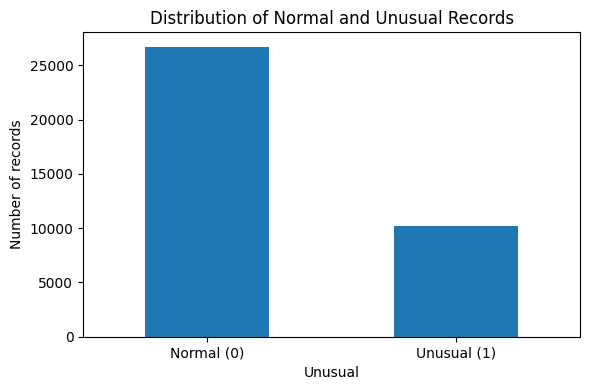

In [4]:
# Check label distribution
print("LABEL COUNTS")
display(train["Unusual"].value_counts().sort_index())

print("\nLABEL PERCENTAGES")
display(
    (train["Unusual"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# Visualize class distribution
import matplotlib.pyplot as plt

train["Unusual"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4),
    rot=0
)

plt.xticks([0, 1], ["Normal (0)", "Unusual (1)"])
plt.ylabel("Number of records")
plt.title("Distribution of Normal and Unusual Records")
plt.tight_layout()
plt.show()

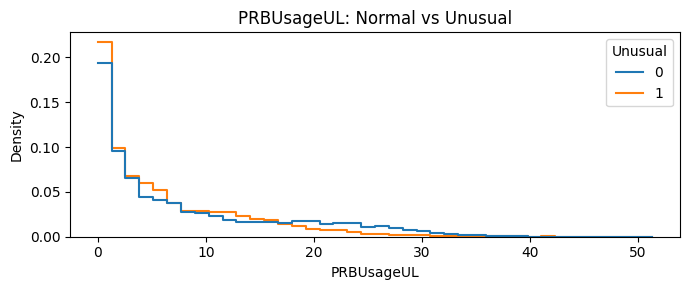

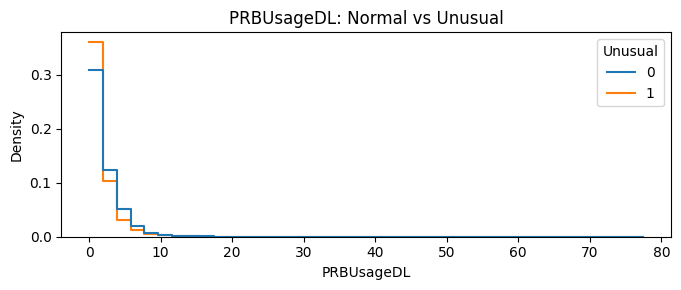

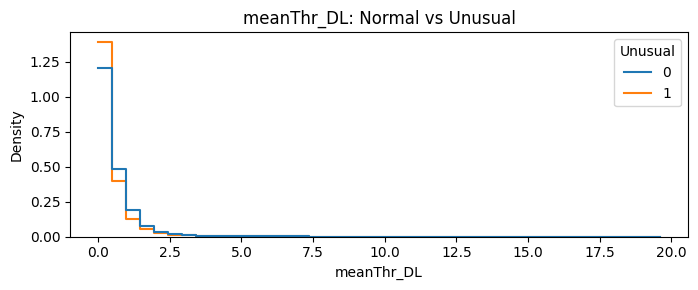

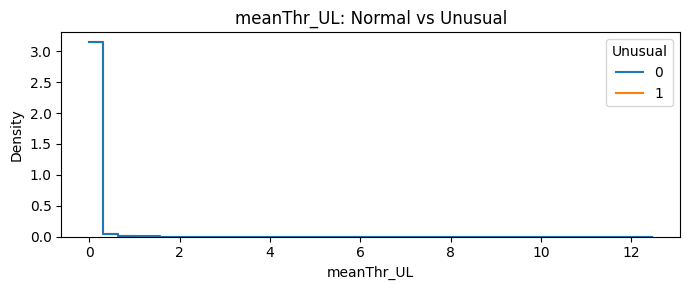

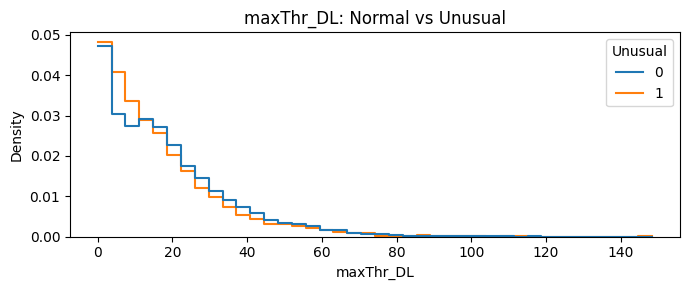

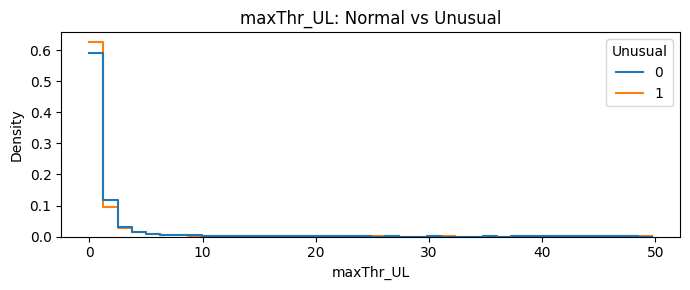

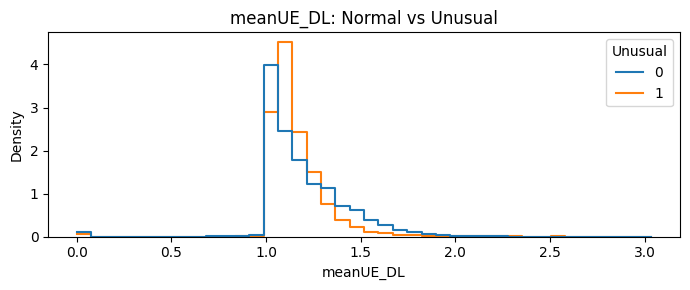

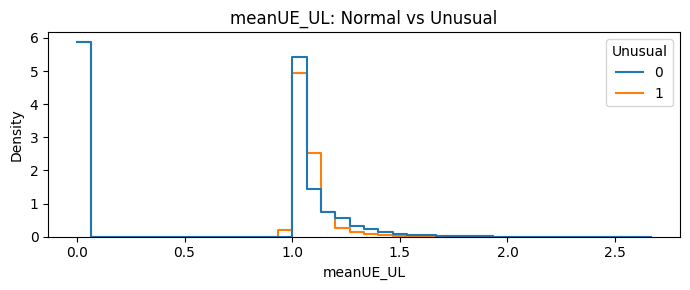

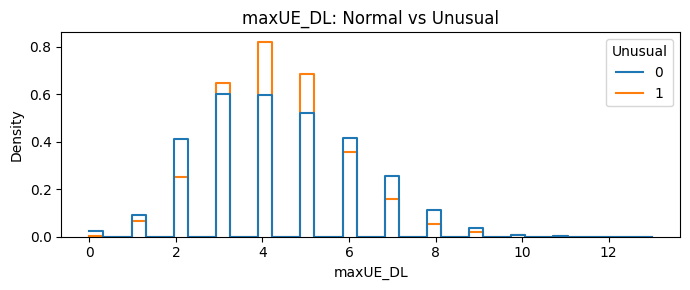

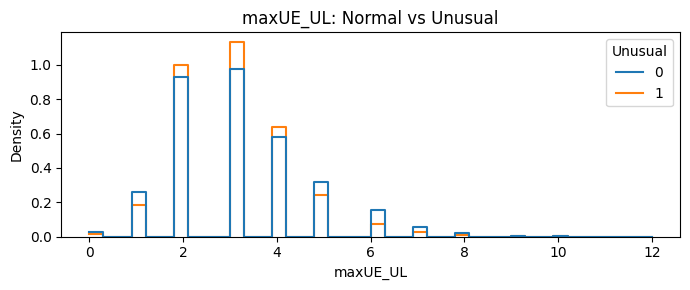

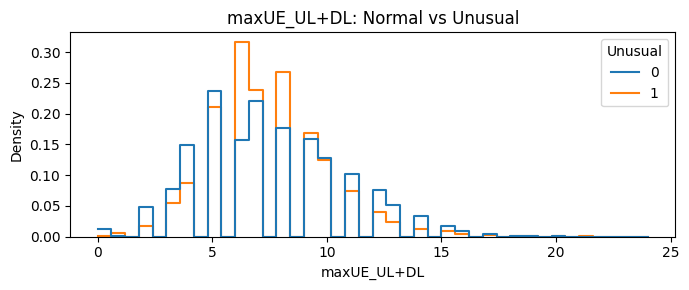

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

features = train.select_dtypes(include="number").columns.drop("Unusual")

# Compare distributions for normal vs unusual records
for feature in features:
    plt.figure(figsize=(7, 3))

    sns.histplot(
        data=train,
        x=feature,
        hue="Unusual",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False
    )

    plt.title(f"{feature}: Normal vs Unusual")
    plt.tight_layout()
    plt.show()

In [6]:
import pandas as pd
import numpy as np

features = train.select_dtypes(include="number").columns.drop("Unusual")

for feature in features:
    normal = train.loc[train["Unusual"] == 0, feature]
    unusual = train.loc[train["Unusual"] == 1, feature]

    print(f"\n{'=' * 65}")
    print(f"FEATURE: {feature}")
    print(f"{'=' * 65}")

    print(f"{'Statistic':<15} {'Normal':>15} {'Unusual':>15}")
    print("-" * 47)

    for stat, func in [
        ("Mean", "mean"),
        ("Median", "median"),
        ("Std Dev", "std"),
        ("25th percentile", None),
        ("75th percentile", None),
        ("Minimum", "min"),
        ("Maximum", "max"),
    ]:
        if func:
            n_val = getattr(normal, func)()
            u_val = getattr(unusual, func)()
        elif stat == "25th percentile":
            n_val, u_val = normal.quantile(0.25), unusual.quantile(0.25)
        else:
            n_val, u_val = normal.quantile(0.75), unusual.quantile(0.75)

        print(f"{stat:<15} {n_val:>15.4f} {u_val:>15.4f}")

    normal_median = normal.median()
    unusual_median = unusual.median()

    if normal_median != 0:
        change = (unusual_median - normal_median) / abs(normal_median) * 100
        print(f"\nMedian change: {change:+.2f}%")


FEATURE: PRBUsageUL
Statistic                Normal         Unusual
-----------------------------------------------
Mean                     8.4454          6.4606
Median                   4.8500          3.9719
Std Dev                  8.9063          7.0119
25th percentile          1.3140          1.0613
75th percentile         13.6420         10.0294
Minimum                  0.0000          0.0000
Maximum                 51.3330         48.6060

Median change: -18.11%

FEATURE: PRBUsageDL
Statistic                Normal         Unusual
-----------------------------------------------
Mean                     2.2314          1.8437
Median                   1.5160          1.1919
Std Dev                  2.3550          1.9690
25th percentile          0.7070          0.6414
75th percentile          3.0320          2.2336
Minimum                  0.0000          0.3972
Maximum                 77.5050         26.2854

Median change: -21.38%

FEATURE: meanThr_DL
Statistic                

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

features = train.select_dtypes(include="number").columns.drop("Unusual")

normal = train[train["Unusual"] == 0]
unusual = train[train["Unusual"] == 1]

results = []

for feature in features:
    n = normal[feature]
    u = unusual[feature]

    pooled_std = np.sqrt((n.var() + u.var()) / 2)

    smd = (u.mean() - n.mean()) / pooled_std if pooled_std > 0 else 0

    auc = roc_auc_score(train["Unusual"], train[feature])

    results.append({
        "Feature": feature,
        "Normal_Mean": n.mean(),
        "Unusual_Mean": u.mean(),
        "SMD": smd,
        "ROC_AUC": auc,
        "Separation_AUC": max(auc, 1 - auc)
    })

results_df = pd.DataFrame(results)

results_df["Abs_SMD"] = results_df["SMD"].abs()

results_df = results_df.sort_values(
    "Separation_AUC",
    ascending=False
)

print("FEATURE SEPARABILITY (BEST FIRST)")
print(results_df.round(4).to_string(index=False))

FEATURE SEPARABILITY (BEST FIRST)
    Feature  Normal_Mean  Unusual_Mean     SMD  ROC_AUC  Separation_AUC  Abs_SMD
  meanUE_UL       0.6741        0.6651 -0.0168   0.5825          0.5825   0.0168
 meanThr_UL       0.0717        0.0590 -0.0680   0.4438          0.5562   0.0680
 PRBUsageUL       8.4454        6.4606 -0.2476   0.4516          0.5484   0.2476
 PRBUsageDL       2.2314        1.8437 -0.1786   0.4534          0.5466   0.1786
 meanThr_DL       0.5900        0.5010 -0.1241   0.4535          0.5465   0.1241
  maxThr_DL      18.4112       16.6547 -0.1119   0.4661          0.5339   0.1119
  maxThr_UL       1.8560        1.6847 -0.0338   0.4663          0.5337   0.0338
  meanUE_DL       1.1957        1.1562 -0.1970   0.4739          0.5261   0.1970
   maxUE_UL       3.1567        3.0406 -0.0857   0.4855          0.5145   0.0857
maxUE_UL+DL       7.4875        7.3335 -0.0528   0.4948          0.5052   0.0528
   maxUE_DL       4.3308        4.2929 -0.0220   0.4997          0.5003   0

In [8]:
import pandas as pd
import numpy as np

features = train.select_dtypes(include="number").columns.drop("Unusual")

# Correlation among numerical features
corr = train[features].corr()

print("HIGHLY CORRELATED FEATURE PAIRS (|correlation| >= 0.70)")
pairs = []

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        value = corr.iloc[i, j]

        if abs(value) >= 0.70:
            pairs.append({
                "Feature 1": features[i],
                "Feature 2": features[j],
                "Correlation": value
            })

if pairs:
    pairs_df = pd.DataFrame(pairs)
    pairs_df["Abs_Correlation"] = pairs_df["Correlation"].abs()
    pairs_df = pairs_df.sort_values("Abs_Correlation", ascending=False)
    print(pairs_df.drop(columns="Abs_Correlation").round(3).to_string(index=False))
else:
    print("No feature pairs meet this threshold.")

# Strongest correlations for each feature
print("\nTOP 3 CORRELATIONS FOR EACH FEATURE")

for feature in features:
    strongest = corr[feature].drop(feature).abs().nlargest(3).index

    print(f"\n{feature}:")
    for other in strongest:
        print(f"  {other}: {corr.loc[feature, other]:.3f}")

HIGHLY CORRELATED FEATURE PAIRS (|correlation| >= 0.70)
 Feature 1   Feature 2  Correlation
  maxUE_DL maxUE_UL+DL        0.967
  maxUE_UL maxUE_UL+DL        0.945
 meanUE_DL maxUE_UL+DL        0.873
 meanUE_DL    maxUE_DL        0.854
  maxUE_DL    maxUE_UL        0.830
 meanUE_DL    maxUE_UL        0.812
PRBUsageDL  meanThr_DL        0.792
PRBUsageUL    maxUE_UL        0.791
PRBUsageUL maxUE_UL+DL        0.768

TOP 3 CORRELATIONS FOR EACH FEATURE

PRBUsageUL:
  maxUE_UL: 0.791
  maxUE_UL+DL: 0.768
  maxUE_DL: 0.691

PRBUsageDL:
  meanThr_DL: 0.792
  maxUE_UL+DL: 0.622
  meanUE_DL: 0.605

meanThr_DL:
  PRBUsageDL: 0.792
  maxThr_DL: 0.629
  maxUE_UL+DL: 0.512

meanThr_UL:
  maxThr_UL: 0.409
  meanThr_DL: 0.299
  PRBUsageUL: 0.287

maxThr_DL:
  meanThr_DL: 0.629
  maxUE_UL+DL: 0.502
  maxUE_DL: 0.493

maxThr_UL:
  meanThr_DL: 0.486
  meanThr_UL: 0.409
  maxThr_DL: 0.337

meanUE_DL:
  maxUE_UL+DL: 0.873
  maxUE_DL: 0.854
  maxUE_UL: 0.812

meanUE_UL:
  PRBUsageUL: 0.546
  maxUE_UL: 0.35

In [9]:
# Records and anomaly rate per cell
cell_stats = (
    train.groupby("CellName")
    .agg(
        Total_Records=("Unusual", "size"),
        Unusual_Count=("Unusual", "sum"),
        Anomaly_Rate=("Unusual", "mean")
    )
    .reset_index()
)

cell_stats["Anomaly_Rate_%"] = (
    cell_stats["Anomaly_Rate"] * 100
).round(2)

cell_stats = cell_stats.sort_values(
    "Anomaly_Rate",
    ascending=False
)

print("CELL-WISE ANOMALY STATISTICS")
print(
    cell_stats[
        ["CellName", "Total_Records", "Unusual_Count", "Anomaly_Rate_%"]
    ].to_string(index=False)
)

print("\nNUMBER OF UNIQUE CELLS:", train["CellName"].nunique())
print("TOTAL RECORDS:", len(train))
print("OVERALL ANOMALY RATE:", round(train["Unusual"].mean() * 100, 2), "%")

CELL-WISE ANOMALY STATISTICS
CellName  Total_Records  Unusual_Count  Anomaly_Rate_%
   5BLTE           1104            319           28.89
  10CLTE           1117            320           28.65
   7ALTE           1083            308           28.44
   5CLTE           1131            321           28.38
   6VLTE           1134            321           28.31
   6WLTE           1133            320           28.24
   3BLTE           1117            315           28.20
   5ALTE           1157            326           28.18
   6ULTE           1129            317           28.08
   1ALTE           1122            315           28.07
   2ALTE           1116            313           28.05
   1CLTE           1120            314           28.04
   8ALTE           1142            319           27.93
   7ULTE           1120            312           27.86
  10BLTE           1107            308           27.82
   7BLTE           1128            313           27.75
   4ALTE           1147            3

In [10]:
import pandas as pd

# Convert Time to minutes after midnight
time_parts = train["Time"].astype(str).str.split(":", expand=True)

train["Time_Minutes"] = (
    pd.to_numeric(time_parts[0], errors="coerce") * 60
    + pd.to_numeric(time_parts[1], errors="coerce")
)

# Group into hourly intervals
train["Hour"] = (train["Time_Minutes"] // 60).astype("Int64")

hour_stats = (
    train.groupby("Hour", dropna=False)
    .agg(
        Total_Records=("Unusual", "size"),
        Unusual_Count=("Unusual", "sum"),
        Anomaly_Rate=("Unusual", "mean")
    )
    .reset_index()
)

hour_stats["Anomaly_Rate_%"] = (
    hour_stats["Anomaly_Rate"] * 100
).round(2)

print("ANOMALY RATE BY HOUR")
print(
    hour_stats[
        ["Hour", "Total_Records", "Unusual_Count", "Anomaly_Rate_%"]
    ].to_string(index=False)
)

print("\nTIME PARSING CHECK")
print("Missing or invalid times:", train["Time_Minutes"].isna().sum())
print("Distinct recorded times:", train["Time"].nunique())
print("Time range:", train["Time"].min(), "to", train["Time"].max())

ANOMALY RATE BY HOUR
 Hour  Total_Records  Unusual_Count  Anomaly_Rate_%
    0           1561            415           26.59
    1           1564            432           27.62
    2           1557            413           26.53
    3           1605            439           27.35
    4           1556            414           26.61
    5           1573            420           26.70
    6           1553            413           26.59
    7           1576            428           27.16
    8           1574            443           28.14
    9           1593            424           26.62
   10           1581            431           27.26
   11           1570            424           27.01
   12           1596            422           26.44
   13           1560            420           26.92
   14           1573            415           26.38
   15           1458            421           28.88
   16           1460            421           28.84
   17           1501            423        

In [11]:
import numpy as np
import pandas as pd

# 1. Compare columns
print("TRAIN COLUMNS:", train.columns.tolist())
print("\nTEST COLUMNS:", test.columns.tolist())

print("\nColumns only in train:", sorted(set(train.columns) - set(test.columns)))
print("Columns only in test:", sorted(set(test.columns) - set(train.columns)))

# 2. Check missing and infinite values in original numeric features
numeric_cols = [
    c for c in train.select_dtypes(include=np.number).columns
    if c not in ["Unusual", "Time_Minutes", "Hour"]
]

print("\nNUMERICAL DATA QUALITY")
for df_name, df in [("Train", train), ("Test", test)]:
    available_cols = [c for c in numeric_cols if c in df.columns]
    numeric = df[available_cols].apply(pd.to_numeric, errors="coerce")

    print(f"\n{df_name}:")
    print("Missing values:", numeric.isna().sum().sum())
    print("Infinite values:", np.isinf(numeric.to_numpy()).sum())

    negative_counts = (numeric < 0).sum()
    print("Columns with negative values:")
    print(negative_counts[negative_counts > 0].to_dict())

# 3. Check whether feature distributions differ between train and test
print("\nTRAIN VS TEST SUMMARY")
for feature in numeric_cols:
    if feature in test.columns:
        print(
            f"{feature:15} "
            f"train median={train[feature].median():.4f}, "
            f"test median={test[feature].median():.4f}"
        )

TRAIN COLUMNS: ['Time', 'CellName', 'PRBUsageUL', 'PRBUsageDL', 'meanThr_DL', 'meanThr_UL', 'maxThr_DL', 'maxThr_UL', 'meanUE_DL', 'meanUE_UL', 'maxUE_DL', 'maxUE_UL', 'maxUE_UL+DL', 'Unusual', 'Time_Minutes', 'Hour']

TEST COLUMNS: ['Time', 'CellName', 'PRBUsageUL', 'PRBUsageDL', 'meanThr_DL', 'meanThr_UL', 'maxThr_DL', 'maxThr_UL', 'meanUE_DL', 'meanUE_UL', 'maxUE_DL', 'maxUE_UL', 'maxUE_UL+DL']

Columns only in train: ['Hour', 'Time_Minutes', 'Unusual']
Columns only in test: []

NUMERICAL DATA QUALITY

Train:
Missing values: 0
Infinite values: 0
Columns with negative values:
{}

Test:
Missing values: 0
Infinite values: 0
Columns with negative values:
{}

TRAIN VS TEST SUMMARY
PRBUsageUL      train median=4.5470, test median=4.4458
PRBUsageDL      train median=1.3792, test median=1.3140
meanThr_DL      train median=0.3560, test median=0.3450
meanThr_UL      train median=0.0400, test median=0.0391
maxThr_DL       train median=14.3040, test median=13.8738
maxThr_UL       train median=0

In [12]:
train_cells = set(train["CellName"].dropna().unique())
test_cells = set(test["CellName"].dropna().unique())

print("TRAIN CELL COUNT:", len(train_cells))
print("TEST CELL COUNT:", len(test_cells))

print("\nCELLS ONLY IN TRAIN:")
print(sorted(train_cells - test_cells))

print("\nCELLS ONLY IN TEST:")
print(sorted(test_cells - train_cells))

print("\nCELLS SHARED BY BOTH:")
print(len(train_cells & test_cells))

# Compare records per cell
train_counts = train["CellName"].value_counts()
test_counts = test["CellName"].value_counts()

cell_comparison = pd.DataFrame({
    "Train_Records": train_counts,
    "Test_Records": test_counts
}).fillna(0).astype(int)

print("\nRECORD COUNTS BY CELL")
print(cell_comparison.sort_index().to_string())

TRAIN CELL COUNT: 33
TEST CELL COUNT: 33

CELLS ONLY IN TRAIN:
[]

CELLS ONLY IN TEST:
[]

CELLS SHARED BY BOTH:
33

RECORD COUNTS BY CELL
          Train_Records  Test_Records
CellName                             
10ALTE             1121           283
10BLTE             1107           296
10CLTE             1117           286
1ALTE              1122           281
1BLTE              1117           287
1CLTE              1120           283
2ALTE              1116           273
3ALTE              1107           289
3BLTE              1117           282
3CLTE              1131           268
4ALTE              1147           254
4BLTE              1134           269
4CLTE              1150           252
5ALTE              1157           245
5BLTE              1104           299
5CLTE              1131           273
6ALTE              1134           267
6BLTE              1112           290
6CLTE              1102           300
6ULTE              1129           271
6VLTE              1134  

In [13]:
# Check repeated time-cell combinations
for name, df in [("TRAIN", train), ("TEST", test)]:
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("Total records:", len(df))
    print("Unique (Time, CellName) pairs:",
          df[["Time", "CellName"]].drop_duplicates().shape[0])

    print("Duplicate (Time, CellName) pairs:",
          df.duplicated(subset=["Time", "CellName"]).sum())

    print("\nRecords per time value:")
    time_counts = df["Time"].value_counts()

    print("Minimum records per time:", time_counts.min())
    print("Maximum records per time:", time_counts.max())
    print("Number of time values:", df["Time"].nunique())

    print("\nFirst 10 time values:")
    print(sorted(df["Time"].dropna().unique())[:10])


TRAIN
Total records: 36904
Unique (Time, CellName) pairs: 3168
Duplicate (Time, CellName) pairs: 33736

Records per time value:
Minimum records per time: 351
Maximum records per time: 423
Number of time values: 96

First 10 time values:
['0:00', '0:15', '0:30', '0:45', '10:00', '10:15', '10:30', '10:45', '11:00', '11:15']

TEST
Total records: 9158
Unique (Time, CellName) pairs: 3040
Duplicate (Time, CellName) pairs: 6118

Records per time value:
Minimum records per time: 67
Maximum records per time: 117
Number of time values: 96

First 10 time values:
['0:00', '0:15', '0:30', '0:45', '10:00', '10:15', '10:30', '10:45', '11:00', '11:15']


In [14]:
# Original measurement columns
features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

keys = ["Time", "CellName"]

# 1. Exact duplicate rows across original columns
original_cols = keys + features + ["Unusual"]

print("EXACT DUPLICATE ROWS:")
print(train[original_cols].duplicated().sum())

# 2. Number of records per time-cell combination
pair_counts = (
    train.groupby(keys, dropna=False)
    .size()
    .reset_index(name="Record_Count")
)

print("\nRECORDS PER TIME-CELL PAIR:")
print(pair_counts["Record_Count"].value_counts().sort_index().to_string())

# 3. Check whether repeated pairs have different feature values
feature_variation = (
    train.groupby(keys)[features]
    .nunique()
)

repeated_pairs = pair_counts[pair_counts["Record_Count"] > 1][keys]

variation = feature_variation.loc[
    pd.MultiIndex.from_frame(repeated_pairs)
]

print("\nREPEATED PAIRS WITH DIFFERING FEATURE VALUES:")
print((variation > 1).any(axis=1).sum())

print("\nREPEATED PAIRS WITH DIFFERING LABELS:")
label_variation = train.groupby(keys)["Unusual"].nunique()
print((label_variation > 1).sum())

EXACT DUPLICATE ROWS:
103

RECORDS PER TIME-CELL PAIR:
Record_Count
5       1
6       6
7      21
8      60
9     191
10    432
11    682
12    799
13    629
14    275
15     72

REPEATED PAIRS WITH DIFFERING FEATURE VALUES:
3168

REPEATED PAIRS WITH DIFFERING LABELS:
3164


In [15]:
# Inspect repeated records for a few time-cell combinations
keys = ["Time", "CellName"]
features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL",
    "Unusual"
]

# Select three groups with many records
pair_counts = train.groupby(keys).size().sort_values(ascending=False)
sample_pairs = pair_counts.head(3).index.tolist()

for time_value, cell_value in sample_pairs:
    print(f"\n{'=' * 70}")
    print(f"TIME: {time_value} | CELL: {cell_value}")
    print("=" * 70)

    group = train.loc[
        (train["Time"] == time_value) &
        (train["CellName"] == cell_value),
        features
    ]

    print("Records:", len(group))
    print("Label counts:")
    print(group["Unusual"].value_counts().sort_index().to_dict())

    display(group.head(10))


TIME: 9:45 | CELL: 1BLTE
Records: 15
Label counts:
{0: 11, 1: 4}


,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
1,22.0438,2.0016,0.5620,0.2697,10.3994,1.1771,1.4480,1.1630,6,5,11,1
647,14.6520,3.1330,1.2260,0.1060,49.0900,1.2540,1.4250,1.0810,6,4,10,0
3938,10.6100,1.5160,0.4430,0.0760,42.5840,2.6970,1.2020,1.0510,6,4,10,0
4479,19.5030,4.5470,1.6460,0.1820,25.6060,4.4270,1.4650,1.2730,6,6,12,0
10038,6.7298,1.0074,0.3191,0.0427,13.5288,0.9873,1.1413,1.0296,4,4,8,1
23942,12.9340,1.6170,0.4930,0.0750,21.5290,1.3270,1.2530,1.0810,5,3,8,0
25593,12.0250,2.3240,0.6040,0.0620,13.5360,0.7090,1.2130,1.0510,6,3,9,0
27052,8.0947,1.3240,0.3111,0.0329,41.0142,0.9566,1.0839,1.0381,5,3,8,1
28105,12.2270,5.2550,1.8320,0.0530,28.3020,1.1440,1.2130,1.0610,5,4,9,0
28398,11.3180,1.6170,0.4770,0.0570,19.3690,2.8530,1.1920,1.0710,5,3,8,0



TIME: 0:00 | CELL: 7WLTE
Records: 15
Label counts:
{0: 11, 1: 4}


,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
6578,0.4040,1.6170,0.6590,0.0200,68.9980,0.2400,1.0510,0.0100,3,2,5,0
7916,0.6060,1.8190,0.2430,0.0210,5.5030,0.5530,1.0110,0.0100,3,2,5,0
9182,0.7108,1.5063,0.2976,0.0220,18.2895,0.8864,1.1399,0.0102,4,4,8,1
11004,0.8080,3.3350,0.9410,0.0370,37.4340,0.6790,1.1920,0.0100,4,3,7,0
11471,1.0110,1.8190,0.1850,0.1100,8.4650,0.8880,1.1520,0.0100,4,3,7,0
14828,3.8400,3.5370,0.7770,0.1340,15.6590,0.7820,1.3240,0.0100,5,4,9,0
16580,0.6060,2.2230,0.2430,0.0340,12.1930,1.1450,1.1120,0.0100,4,3,7,0
19100,1.4500,2.4503,0.3616,0.0729,19.3692,2.9571,1.2159,0.0106,5,3,8,1
23261,0.3099,1.2026,0.1992,0.0221,10.8717,0.3613,1.0649,0.0106,3,2,5,1
24354,0.5040,1.0278,0.0456,0.0253,1.4942,1.1642,1.1191,0.0106,5,2,7,1



TIME: 0:15 | CELL: 5ALTE
Records: 15
Label counts:
{0: 11, 1: 4}


,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
298,2.6270,0.8080,0.2320,0.0200,8.0740,0.5590,1.0310,1.0110,3,2,5,0
2795,2.2823,0.6089,0.1956,0.0102,14.6155,0.1665,1.0303,1.0459,2,3,5,1
3498,2.5260,0.5050,0.1110,0.0180,7.0060,0.3790,1.0410,1.0210,2,2,4,0
7825,2.6270,1.0110,0.1910,0.0440,7.5110,0.3440,1.0510,1.0210,3,2,5,0
10437,2.0210,1.4150,0.8150,0.0320,32.7230,0.2490,1.0510,1.0210,3,2,5,0
15643,6.9720,0.7070,0.1270,0.0210,6.4600,0.4300,1.0610,1.0310,3,3,6,0
19219,3.4885,1.1527,0.2230,0.0243,18.3172,0.9935,1.0418,1.0662,4,2,6,1
21785,7.7810,0.9090,0.1870,0.0360,13.3890,0.6120,1.0910,1.0210,3,3,6,0
22065,2.0210,1.2130,0.6910,0.0410,30.8300,1.2690,1.0210,1.0110,2,2,4,0
22481,4.2440,0.6060,0.1030,0.0420,4.4490,0.5490,1.0710,1.0110,3,2,5,0


In [16]:
# Original input features only — exclude Time, CellName, and engineered columns
features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

# Group identical numerical feature vectors
vector_stats = (
    train.groupby(features, dropna=False)["Unusual"]
    .agg(["size", "nunique", "min", "max"])
    .reset_index()
)

# Vectors that occur more than once with conflicting labels
conflicts = vector_stats[
    (vector_stats["size"] > 1) &
    (vector_stats["nunique"] > 1)
]

print("UNIQUE NUMERICAL FEATURE VECTORS:", len(vector_stats))
print("REPEATED NUMERICAL VECTORS:", (vector_stats["size"] > 1).sum())
print("VECTORS WITH CONFLICTING LABELS:", len(conflicts))

print("\nEXAMPLES OF CONFLICTING VECTORS:")
if len(conflicts) > 0:
    print(conflicts.head(10).to_string(index=False))
else:
    print("No conflicting labels found for identical numerical vectors.")

# Also check how often each label occurs among repeated vectors
repeated = vector_stats[vector_stats["size"] > 1]

print("\nTOTAL ROWS BELONGING TO REPEATED VECTORS:",
      repeated["size"].sum())

UNIQUE NUMERICAL FEATURE VECTORS: 36740
REPEATED NUMERICAL VECTORS: 9
VECTORS WITH CONFLICTING LABELS: 0

EXAMPLES OF CONFLICTING VECTORS:
No conflicting labels found for identical numerical vectors.

TOTAL ROWS BELONGING TO REPEATED VECTORS: 173


In [17]:
features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

cell_feature_stats = train.groupby("CellName")[features].mean()

print("FEATURE VARIATION ACROSS CELLS")
print("Each row is a cell; values are feature means.\n")
print(cell_feature_stats.round(3).to_string())

print("\nCROSS-CELL VARIATION SUMMARY")
print("Feature            Min cell mean   Max cell mean   Ratio")

for feature in features:
    values = cell_feature_stats[feature]
    minimum = values.min()
    maximum = values.max()

    ratio = maximum / minimum if minimum > 0 else float("nan")

    print(
        f"{feature:<18} {minimum:>12.4f} "
        f"{maximum:>14.4f} {ratio:>9.2f}"
    )

FEATURE VARIATION ACROSS CELLS
Each row is a cell; values are feature means.

          PRBUsageUL  PRBUsageDL  meanThr_DL  meanThr_UL  maxThr_DL  maxThr_UL  meanUE_DL  meanUE_UL  maxUE_DL  maxUE_UL  maxUE_UL+DL
CellName                                                                                                                             
10ALTE        11.202       1.916       0.591       0.065     19.334      1.400      1.185      1.080     4.360     3.392        7.752
10BLTE         4.609       0.927       0.285       0.038     13.178      0.907      1.078      1.028     3.229     2.353        5.582
10CLTE         5.074       1.008       0.267       0.031     10.962      0.736      1.076      1.034     3.295     2.539        5.834
1ALTE         13.732       2.377       0.728       0.084     23.603      1.944      1.273      1.103     5.164     3.750        8.914
1BLTE         13.339       2.331       0.736       0.082     25.345      1.865      1.261      1.083     5.160     3.6

In [18]:
import pandas as pd
import numpy as np

features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

# Calculate each cell's normal and unusual class means
cell_class_means = (
    train.groupby(["CellName", "Unusual"])[features]
    .mean()
    .unstack("Unusual")
)

results = []

for feature in features:
    normal_means = cell_class_means[(feature, 0)]
    unusual_means = cell_class_means[(feature, 1)]

    differences = unusual_means - normal_means

    results.append({
        "Feature": feature,
        "Cells_Compared": differences.notna().sum(),
        "Cells_Unusual_Higher": (differences > 0).sum(),
        "Cells_Unusual_Lower": (differences < 0).sum(),
        "Median_Within_Cell_Difference": differences.median(),
        "Mean_Within_Cell_Difference": differences.mean()
    })

results_df = pd.DataFrame(results)

print("WITHIN-CELL NORMAL VS UNUSUAL COMPARISON")
print(results_df.round(4).to_string(index=False))

WITHIN-CELL NORMAL VS UNUSUAL COMPARISON
    Feature  Cells_Compared  Cells_Unusual_Higher  Cells_Unusual_Lower  Median_Within_Cell_Difference  Mean_Within_Cell_Difference
 PRBUsageUL              33                     3                   30                        -0.8355                      -1.9541
 PRBUsageDL              33                     6                   27                        -0.3723                      -0.3899
 meanThr_DL              33                     8                   25                        -0.0878                      -0.0877
 meanThr_UL              33                     9                   24                        -0.0169                      -0.0125
  maxThr_DL              33                     8                   25                        -2.1403                      -1.7228
  maxThr_UL              33                    11                   22                        -0.2002                      -0.1599
  meanUE_DL              33               

In [19]:
import pandas as pd

features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

results = []

for feature in features:
    q1 = train[feature].quantile(0.25)
    q3 = train[feature].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    row = {
        "Feature": feature,
        "IQR_Lower": lower,
        "IQR_Upper": upper,
        "Overall_Outliers": (
            (train[feature] < lower) | (train[feature] > upper)
        ).sum(),
        "Normal_Outliers": (
            (train.loc[train["Unusual"] == 0, feature] < lower) |
            (train.loc[train["Unusual"] == 0, feature] > upper)
        ).sum(),
        "Unusual_Outliers": (
            (train.loc[train["Unusual"] == 1, feature] < lower) |
            (train.loc[train["Unusual"] == 1, feature] > upper)
        ).sum()
    }

    results.append(row)

outlier_df = pd.DataFrame(results)

print("IQR OUTLIER ANALYSIS")
print(outlier_df.round(3).to_string(index=False))

IQR OUTLIER ANALYSIS
    Feature  IQR_Lower  IQR_Upper  Overall_Outliers  Normal_Outliers  Unusual_Outliers
 PRBUsageUL    -15.459     29.000               921              800               121
 PRBUsageDL     -2.473      6.007              1983             1563               420
 meanThr_DL     -0.732      1.600              2247             1740               507
 meanThr_UL     -0.058      0.155              2360             1890               470
  maxThr_DL    -23.511     54.573              1362             1027               335
  maxThr_UL     -0.961      2.580              4053             3048              1005
  meanUE_DL      0.721      1.604              1805             1567               238
  meanUE_UL     -1.578      2.657                 1                1                 0
   maxUE_DL      0.000      8.000               507              400               107
   maxUE_UL     -1.000      7.000               269              210                59
maxUE_UL+DL     -1.000

In [20]:
import pandas as pd

# Use original Time and CellName columns
time_cell_stats = (
    train.groupby(["Time", "CellName"])["Unusual"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

time_cell_stats.rename(columns={
    "count": "Records",
    "sum": "Unusual_Count",
    "mean": "Anomaly_Rate"
}, inplace=True)

time_cell_stats["Anomaly_Rate_%"] = (
    time_cell_stats["Anomaly_Rate"] * 100
).round(2)

print("TIME-CELL GROUP SUMMARY")
print("Total time-cell groups:", len(time_cell_stats))
print("Groups with fewer than 5 records:",
      (time_cell_stats["Records"] < 5).sum())

print("\nLOWEST 10 ANOMALY-RATE GROUPS")
print(
    time_cell_stats.sort_values("Anomaly_Rate").head(10)[
        ["Time", "CellName", "Records", "Unusual_Count", "Anomaly_Rate_%"]
    ].to_string(index=False)
)

print("\nHIGHEST 10 ANOMALY-RATE GROUPS")
print(
    time_cell_stats.sort_values("Anomaly_Rate", ascending=False).head(10)[
        ["Time", "CellName", "Records", "Unusual_Count", "Anomaly_Rate_%"]
    ].to_string(index=False)
)

print("\nDISTRIBUTION OF GROUP ANOMALY RATES")
print(
    time_cell_stats["Anomaly_Rate"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(4).to_string()
)

TIME-CELL GROUP SUMMARY
Total time-cell groups: 3168
Groups with fewer than 5 records: 0

LOWEST 10 ANOMALY-RATE GROUPS
 Time CellName  Records  Unusual_Count  Anomaly_Rate_%
 9:30    3CLTE        8              0            0.00
 3:00    4CLTE        9              0            0.00
 9:30    7ALTE        6              0            0.00
 7:30    1BLTE       10              0            0.00
10:15    4BLTE       12              1            8.33
 5:30    3CLTE       12              1            8.33
 4:30    8CLTE       12              1            8.33
14:45    4CLTE       11              1            9.09
22:45    7VLTE       11              1            9.09
 6:15    8BLTE       11              1            9.09

HIGHEST 10 ANOMALY-RATE GROUPS
 Time CellName  Records  Unusual_Count  Anomaly_Rate_%
16:30    7ULTE        7              4           57.14
21:15    5CLTE        6              3           50.00
20:00    2ALTE        8              4           50.00
17:15    1ALTE        8

In [21]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

X = train[features]
y = train["Unusual"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced")
)

model.fit(X_train, y_train)

pred = model.predict(X_val)
prob = model.predict_proba(X_val)[:, 1]

print("VALIDATION ROC-AUC:", round(roc_auc_score(y_val, prob), 4))
print("VALIDATION PR-AUC:", round(average_precision_score(y_val, prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_val, pred, digits=4))

print("CONFUSION MATRIX [ [TN, FP], [FN, TP] ]")
print(confusion_matrix(y_val, pred))

VALIDATION ROC-AUC: 0.6648
VALIDATION PR-AUC: 0.4149

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8214    0.5911    0.6875      5344
           1     0.3819    0.6627    0.4846      2037

    accuracy                         0.6109      7381
   macro avg     0.6016    0.6269    0.5860      7381
weighted avg     0.7001    0.6109    0.6315      7381

CONFUSION MATRIX [ [TN, FP], [FN, TP] ]
[[3159 2185]
 [ 687 1350]]


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_val)
rf_prob = rf.predict_proba(X_val)[:, 1]

print("RANDOM FOREST VALIDATION RESULTS")
print("ROC-AUC:", round(roc_auc_score(y_val, rf_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, rf_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_val, rf_pred, digits=4))

print("CONFUSION MATRIX [ [TN, FP], [FN, TP] ]")
print(confusion_matrix(y_val, rf_pred))

print("\nFEATURE IMPORTANCE")
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance.round(4).to_string())

RANDOM FOREST VALIDATION RESULTS
ROC-AUC: 0.9777
PR-AUC: 0.9605

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9495    0.9710    0.9601      5344
           1     0.9191    0.8645    0.8910      2037

    accuracy                         0.9416      7381
   macro avg     0.9343    0.9178    0.9255      7381
weighted avg     0.9411    0.9416    0.9410      7381

CONFUSION MATRIX [ [TN, FP], [FN, TP] ]
[[5189  155]
 [ 276 1761]]

FEATURE IMPORTANCE
meanUE_UL      0.4824
meanUE_DL      0.1096
PRBUsageDL     0.1055
PRBUsageUL     0.1021
meanThr_UL     0.0415
maxUE_UL+DL    0.0304
meanThr_DL     0.0290
maxThr_UL      0.0265
maxThr_DL      0.0262
maxUE_DL       0.0256
maxUE_UL       0.0212


In [23]:
import pandas as pd
import numpy as np

feature = "meanUE_UL"

print("OVERALL DISTRIBUTION BY LABEL")
print(
    train.groupby("Unusual")[feature]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(5)
    .to_string()
)

print("\nVALUE FREQUENCIES BY LABEL")
for label in [0, 1]:
    print(f"\nUnusual = {label}")
    print(
        train.loc[train["Unusual"] == label, feature]
        .round(4)
        .value_counts()
        .head(15)
        .to_string()
    )

print("\nMEAN meanUE_UL BY CELL AND LABEL")
cell_means = (
    train.groupby(["CellName", "Unusual"])[feature]
    .mean()
    .unstack("Unusual")
    .rename(columns={0: "Normal_Mean", 1: "Unusual_Mean"})
)

cell_means["Difference"] = (
    cell_means["Unusual_Mean"] - cell_means["Normal_Mean"]
)

print(cell_means.round(5).to_string())

print("\nCORRELATION WITH LABEL")
print(
    "Pearson correlation:",
    round(train[feature].corr(train["Unusual"]), 5)
)

OVERALL DISTRIBUTION BY LABEL
         count     mean      std  min  median     max
Unusual                                              
0        26721  0.67413  0.54362  0.0  1.0110  2.6680
1        10183  0.66511  0.53212  0.0  1.0243  2.1128

VALUE FREQUENCIES BY LABEL

Unusual = 0
meanUE_UL
0.010    10257
1.011     3524
1.021     2556
1.031     1452
1.041      879
1.051      679
1.061      566
1.071      458
1.081      454
1.091      404
1.101      361
1.112      338
1.122      267
1.132      265
1.152      257

Unusual = 1
meanUE_UL
0.0104    543
0.0106    528
0.0102    516
0.0101    505
0.0105    496
0.0103    491
0.0107    484
0.0100    362
0.0000     60
1.0336     14
1.0592     13
1.0644     12
1.0500     12
1.0646     12
1.0668     12

MEAN meanUE_UL BY CELL AND LABEL
Unusual   Normal_Mean  Unusual_Mean  Difference
CellName                                       
10ALTE        1.08473       1.06732    -0.01742
10BLTE        1.02705       1.03090     0.00385
10CLTE        1.031

In [24]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

features = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL", "maxUE_UL+DL"
]

X = train[features]
y = train["Unusual"]

# Each Time-CellName combination stays entirely in one split
groups = train["Time"].astype(str) + "_" + train["CellName"].astype(str)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(splitter.split(X, y, groups=groups))

X_train_group, X_val_group = X.iloc[train_idx], X.iloc[val_idx]
y_train_group, y_val_group = y.iloc[train_idx], y.iloc[val_idx]

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Overlapping groups:", len(
    set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])
))

rf_group = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_group.fit(X_train_group, y_train_group)

prob_group = rf_group.predict_proba(X_val_group)[:, 1]
pred_group = rf_group.predict(X_val_group)

print("\nGROUP-HOLDOUT VALIDATION")
print("ROC-AUC:", round(roc_auc_score(y_val_group, prob_group), 4))
print("PR-AUC:", round(average_precision_score(y_val_group, prob_group), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_val_group, pred_group, digits=4))

print("CONFUSION MATRIX [ [TN, FP], [FN, TP] ]")
print(confusion_matrix(y_val_group, pred_group))

Training rows: 29434
Validation rows: 7470
Overlapping groups: 0

GROUP-HOLDOUT VALIDATION
ROC-AUC: 0.977
PR-AUC: 0.9589

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9507    0.9703    0.9604      5429
           1     0.9165    0.8662    0.8907      2041

    accuracy                         0.9419      7470
   macro avg     0.9336    0.9183    0.9256      7470
weighted avg     0.9414    0.9419    0.9414      7470

CONFUSION MATRIX [ [TN, FP], [FN, TP] ]
[[5268  161]
 [ 273 1768]]


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Remove meanUE_UL only
features_without = [f for f in features if f != "meanUE_UL"]

rf_without = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_without.fit(
    X_train_group[features_without],
    y_train_group
)

prob_without = rf_without.predict_proba(
    X_val_group[features_without]
)[:, 1]

print("ABLATION RESULTS")
print("Features removed: meanUE_UL")
print("ROC-AUC:", round(roc_auc_score(y_val_group, prob_without), 4))
print("PR-AUC:", round(average_precision_score(y_val_group, prob_without), 4))

print("\nCOMPARISON WITH ALL FEATURES")
print("All features ROC-AUC: 0.9770")
print("All features PR-AUC:  0.9589")

ABLATION RESULTS
Features removed: meanUE_UL
ROC-AUC: 0.9482
PR-AUC: 0.906

COMPARISON WITH ALL FEATURES
All features ROC-AUC: 0.9770
All features PR-AUC:  0.9589


In [26]:
import pandas as pd
import numpy as np

feature = "meanUE_UL"

print("TRAIN DISTRIBUTION")
print(train[feature].describe(percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).round(5))

print("\nTEST DISTRIBUTION")
print(test[feature].describe(percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).round(5))

# Compare the proportion of values near 0.01
threshold = 0.02

train_low = (train[feature] <= threshold).mean() * 100
test_low = (test[feature] <= threshold).mean() * 100

print(f"\nPercentage with {feature} <= {threshold}:")
print(f"Train: {train_low:.2f}%")
print(f"Test:  {test_low:.2f}%")

# Check cell-specific low-value rates
train_rates = train.assign(
    LowValue=train[feature] <= threshold
).groupby("CellName")["LowValue"].mean()

test_rates = test.assign(
    LowValue=test[feature] <= threshold
).groupby("CellName")["LowValue"].mean()

comparison = pd.DataFrame({
    "Train_LowValue_%": train_rates * 100,
    "Test_LowValue_%": test_rates * 100
})

comparison["Difference_pp"] = (
    comparison["Test_LowValue_%"] - comparison["Train_LowValue_%"]
)

print("\nCELL-WISE LOW-VALUE RATE COMPARISON")
print(comparison.round(2).to_string())

TRAIN DISTRIBUTION
count    36904.00000
mean         0.67164
std          0.54048
min          0.00000
1%           0.01000
10%          0.01000
25%          0.01000
50%          1.01100
75%          1.06870
90%          1.17907
99%          1.53600
max          2.66800
Name: meanUE_UL, dtype: float64

TEST DISTRIBUTION
count    9158.00000
mean        0.66676
std         0.53962
min         0.00000
1%          0.01000
10%         0.01000
25%         0.01000
50%         1.01100
75%         1.06140
90%         1.17200
99%         1.54030
max         2.21520
Name: meanUE_UL, dtype: float64

Percentage with meanUE_UL <= 0.02:
Train: 39.18%
Test:  39.50%

CELL-WISE LOW-VALUE RATE COMPARISON
          Train_LowValue_%  Test_LowValue_%  Difference_pp
CellName                                                  
10ALTE                0.36             0.00          -0.36
10BLTE                0.27             0.00          -0.27
10CLTE                0.18             0.00          -0.18
1ALTE     

In [27]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

X_cell = train[["CellName"]]
y = train["Unusual"]

X_train_cell = X_cell.iloc[train_idx]
X_val_cell = X_cell.iloc[val_idx]
y_train_cell = y.iloc[train_idx]
y_val_cell = y.iloc[val_idx]

cell_model = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

cell_model.fit(X_train_cell, y_train_cell)

cell_prob = cell_model.predict_proba(X_val_cell)[:, 1]

print("CELL-NAME-ONLY BASELINE")
print("ROC-AUC:", round(roc_auc_score(y_val_cell, cell_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val_cell, cell_prob), 4))

print("\nREFERENCE: NUMERICAL RANDOM FOREST")
print("ROC-AUC: 0.9770")
print("PR-AUC:  0.9589")

CELL-NAME-ONLY BASELINE
ROC-AUC: 0.5044
PR-AUC: 0.2747

REFERENCE: NUMERICAL RANDOM FOREST
ROC-AUC: 0.9770
PR-AUC:  0.9589


In [28]:
import pandas as pd
import numpy as np

feature_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

X_train_split = train.iloc[train_idx][feature_cols]
X_val_split = train.iloc[val_idx][feature_cols]

# Count exact feature vectors shared across the split
train_vectors = set(map(tuple, X_train_split.to_numpy()))
val_vectors = list(map(tuple, X_val_split.to_numpy()))

shared_count = sum(v in train_vectors for v in val_vectors)

print("Validation rows:", len(X_val_split))
print("Exact feature vectors also in training:", shared_count)
print("Percentage shared:", round(100 * shared_count / len(X_val_split), 4), "%")

Validation rows: 7470
Exact feature vectors also in training: 57
Percentage shared: 0.7631 %


In [29]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

feature_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

X = train[feature_cols]
y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_cell, val_idx_cell = next(
    splitter.split(X, y, groups=groups)
)

X_train_cell = X.iloc[train_idx_cell]
X_val_cell = X.iloc[val_idx_cell]
y_train_cell = y.iloc[train_idx_cell]
y_val_cell = y.iloc[val_idx_cell]

print("Training cells:", groups.iloc[train_idx_cell].nunique())
print("Validation cells:", groups.iloc[val_idx_cell].nunique())
print(
    "Overlapping cells:",
    len(set(groups.iloc[train_idx_cell]) & set(groups.iloc[val_idx_cell]))
)

rf_cell = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_cell.fit(X_train_cell, y_train_cell)
pred = rf_cell.predict_proba(X_val_cell)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_val_cell, pred), 4))
print("PR-AUC:", round(average_precision_score(y_val_cell, pred), 4))

Training cells: 26
Validation cells: 7
Overlapping cells: 0
ROC-AUC: 0.9783
PR-AUC: 0.9671


In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

dt = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42
)

dt.fit(X_train_cell, y_train_cell)

pred_dt = dt.predict_proba(X_val_cell)[:, 1]

print("Shallow Decision Tree")
print("ROC-AUC:", round(roc_auc_score(y_val_cell, pred_dt), 4))
print("PR-AUC:", round(average_precision_score(y_val_cell, pred_dt), 4))

print("\nFeature rules:")
from sklearn.tree import export_text
print(export_text(dt, feature_names=feature_cols))

Shallow Decision Tree
ROC-AUC: 0.8669
PR-AUC: 0.7054

Feature rules:
|--- meanUE_UL <= 0.01
|   |--- meanUE_UL <= 0.00
|   |   |--- maxUE_UL+DL <= 0.50
|   |   |   |--- class: 0
|   |   |--- maxUE_UL+DL >  0.50
|   |   |   |--- class: 1
|   |--- meanUE_UL >  0.00
|   |   |--- PRBUsageDL <= 0.40
|   |   |   |--- class: 0
|   |   |--- PRBUsageDL >  0.40
|   |   |   |--- class: 0
|--- meanUE_UL >  0.01
|   |--- meanUE_UL <= 1.01
|   |   |--- class: 1
|   |--- meanUE_UL >  1.01
|   |   |--- meanUE_UL <= 1.02
|   |   |   |--- class: 0
|   |   |--- meanUE_UL >  1.02
|   |   |   |--- class: 1



In [31]:
import pandas as pd

train["meanUE_UL_bin"] = pd.cut(
    train["meanUE_UL"],
    bins=[-float("inf"), 0.01, 0.5, 1.01, 1.02, float("inf")],
    labels=[
        "<= 0.01",
        "0.01–0.5",
        "0.5–1.01",
        "1.01–1.02",
        "> 1.02"
    ]
)

summary = train.groupby(
    "meanUE_UL_bin", observed=False
)["Unusual"].agg(["count", "mean"])

summary["anomaly_rate_%"] = (summary["mean"] * 100).round(2)

print(summary.drop(columns="mean"))

               count  anomaly_rate_%
meanUE_UL_bin                       
<= 0.01        10891            3.87
0.01–0.5        3569          100.00
0.5–1.01         454          100.00
1.01–1.02       3948           10.74
> 1.02         18042           29.45


In [32]:
mask = train["meanUE_UL"].between(0.01, 1.01, inclusive="neither")
subset = train.loc[mask]

print("Rows in suspicious range:", len(subset))
print("Anomalies:", int(subset["Unusual"].sum()))
print("Anomaly rate:", round(subset["Unusual"].mean() * 100, 2), "%")
print("Cells represented:", subset["CellName"].nunique())

print("\nPer-cell breakdown:")
print(
    subset.groupby("CellName")["Unusual"]
    .agg(rows="count", anomaly_rate="mean")
    .assign(anomaly_rate_pct=lambda x: (x["anomaly_rate"] * 100).round(2))
    .drop(columns="anomaly_rate")
    .sort_values("rows", ascending=False)
    .to_string()
)

Rows in suspicious range: 4022
Anomalies: 4022
Anomaly rate: 100.0 %
Cells represented: 33

Per-cell breakdown:
          rows  anomaly_rate_pct
CellName                        
6VLTE      296             100.0
6WLTE      292             100.0
6ALTE      290             100.0
7ALTE      285             100.0
6ULTE      283             100.0
7ULTE      279             100.0
6CLTE      277             100.0
7WLTE      275             100.0
6BLTE      272             100.0
7BLTE      272             100.0
7CLTE      269             100.0
2ALTE      243             100.0
7VLTE      236             100.0
9BLTE       51             100.0
10BLTE      50             100.0
3CLTE       44             100.0
9ALTE       40             100.0
10CLTE      36             100.0
5ALTE       35             100.0
8CLTE       33             100.0
5CLTE       27             100.0
4ALTE       26             100.0
8BLTE       21             100.0
10ALTE      17             100.0
5BLTE       15             100

In [33]:
import pandas as pd

bins = [-float("inf"), 0.01, 1.01, float("inf")]
labels = ["<= 0.01", "0.01–1.01", "> 1.01"]

train_bins = pd.cut(train["meanUE_UL"], bins=bins, labels=labels)
test_bins = pd.cut(test["meanUE_UL"], bins=bins, labels=labels)

print("TRAIN DISTRIBUTION")
print(train_bins.value_counts().sort_index())

print("\nTEST DISTRIBUTION")
print(test_bins.value_counts().sort_index())

print("\nTest rows in the suspicious range (0.01, 1.01):")
print(
    test["meanUE_UL"].gt(0.01).mul(test["meanUE_UL"].lt(1.01)).sum()
)

TRAIN DISTRIBUTION
meanUE_UL
<= 0.01      10891
0.01–1.01     4023
> 1.01       21990
Name: count, dtype: int64

TEST DISTRIBUTION
meanUE_UL
<= 0.01      2773
0.01–1.01     947
> 1.01       5438
Name: count, dtype: int64

Test rows in the suspicious range (0.01, 1.01):
947


In [34]:
import pandas as pd

ranges = [
    ("0 to 0.01", 0, 0.01),
    ("0.01 to 0.1", 0.01, 0.1),
    ("0.1 to 0.5", 0.1, 0.5),
    ("0.5 to 1.01", 0.5, 1.01),
    ("1.01 to 1.02", 1.01, 1.02),
    ("Above 1.02", 1.02, float("inf"))
]

for name, low, high in ranges:
    mask = (
        (train["meanUE_UL"] > low) &
        (train["meanUE_UL"] <= high)
    )
    subset = train.loc[mask]

    print(
        f"{name:15} | rows={len(subset):5} | "
        f"anomaly_rate={subset['Unusual'].mean() * 100 if len(subset) else 0:.2f}%"
    )

0 to 0.01       | rows=10619 | anomaly_rate=3.41%
0.01 to 0.1     | rows= 3569 | anomaly_rate=100.00%
0.1 to 0.5      | rows=    0 | anomaly_rate=0.00%
0.5 to 1.01     | rows=  454 | anomaly_rate=100.00%
1.01 to 1.02    | rows= 3948 | anomaly_rate=10.74%
Above 1.02      | rows=18042 | anomaly_rate=29.45%


In [35]:
print("Unique values:", train["meanUE_UL"].nunique())

print("\nMost frequent values:")
print(train["meanUE_UL"].value_counts().head(20).to_string())

print("\nUnique values between 0.01 and 1.01:")
values = sorted(
    train.loc[
        train["meanUE_UL"].between(0.01, 1.01, inclusive="neither"),
        "meanUE_UL"
    ].unique()
)

print(values[:50])

Unique values: 2171

Most frequent values:
meanUE_UL
0.0100    10619
1.0110     3525
1.0210     2559
1.0310     1456
1.0410      884
1.0510      685
1.0610      574
0.0104      543
0.0106      528
0.0102      516
0.0101      505
0.0105      496
0.0103      491
0.0107      484
1.0710      465
1.0810      455
1.0910      409
1.1010      365
1.1120      341
0.0000      272

Unique values between 0.01 and 1.01:
[np.float64(0.0101), np.float64(0.0102), np.float64(0.0103), np.float64(0.0104), np.float64(0.0105), np.float64(0.0106), np.float64(0.0107), np.float64(0.0108), np.float64(0.993), np.float64(0.9931), np.float64(0.9932), np.float64(0.9933), np.float64(0.9934), np.float64(0.9935), np.float64(0.9936), np.float64(0.9937), np.float64(0.9938), np.float64(0.9939), np.float64(0.994), np.float64(0.9941), np.float64(0.9942), np.float64(0.9943), np.float64(0.9945), np.float64(0.9946), np.float64(0.9947), np.float64(0.9948), np.float64(0.9949), np.float64(0.995), np.float64(0.9952), np.float64(

In [36]:
import pandas as pd

summary = (
    train.groupby("meanUE_UL")["Unusual"]
    .agg(rows="count", anomalies="sum", anomaly_rate="mean")
    .sort_values("rows", ascending=False)
    .head(20)
)

summary["anomaly_rate_%"] = (summary["anomaly_rate"] * 100).round(2)

print(summary.drop(columns="anomaly_rate").to_string())

            rows  anomalies  anomaly_rate_%
meanUE_UL                                  
0.0100     10619        362            3.41
1.0110      3525          1            0.03
1.0210      2559          3            0.12
1.0310      1456          4            0.27
1.0410       884          5            0.57
1.0510       685          6            0.88
1.0610       574          8            1.39
0.0104       543        543          100.00
0.0106       528        528          100.00
0.0102       516        516          100.00
0.0101       505        505          100.00
0.0105       496        496          100.00
0.0103       491        491          100.00
0.0107       484        484          100.00
1.0710       465          7            1.51
1.0810       455          1            0.22
1.0910       409          5            1.22
1.1010       365          4            1.10
1.1120       341          3            0.88
0.0000       272         60           22.06


In [37]:
import pandas as pd

normal_group = train[train["meanUE_UL"] == 0.0100]

unusual_group = train[
    train["meanUE_UL"].isin([0.0101, 0.0102, 0.0103, 0.0104,
                             0.0105, 0.0106, 0.0107])
]

compare_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

comparison = pd.DataFrame({
    "meanUE_UL=0.0100 (mostly normal)": normal_group[compare_cols].median(),
    "meanUE_UL=0.0101–0.0107 (unusual)": unusual_group[compare_cols].median()
})

comparison["relative_change_%"] = (
    (comparison.iloc[:, 1] - comparison.iloc[:, 0])
    / comparison.iloc[:, 0].replace(0, float("nan")) * 100
).round(2)

print("Group sizes:", len(normal_group), len(unusual_group))
print(comparison.to_string())

Group sizes: 10619 3563
             meanUE_UL=0.0100 (mostly normal)  meanUE_UL=0.0101–0.0107 (unusual)  relative_change_%
PRBUsageUL                             1.3140                             0.9007             -31.45
PRBUsageDL                             1.6170                             1.3198             -18.38
meanThr_DL                             0.3596                             0.2825             -21.44
meanThr_UL                             0.0420                             0.0336             -20.00
maxThr_DL                             13.7400                            11.0703             -19.43
maxThr_UL                              0.7400                             0.6151             -16.88
meanUE_DL                              1.1520                             1.1167              -3.06
maxUE_DL                               4.0000                             4.0000               0.00
maxUE_UL                               3.0000                             3.

In [38]:
import pandas as pd

train["meanUE_UL_group"] = "Other"
train.loc[train["meanUE_UL"] == 0.0100, "meanUE_UL_group"] = "Exactly 0.0100"

train.loc[
    train["meanUE_UL"].isin(
        [0.0101, 0.0102, 0.0103, 0.0104, 0.0105, 0.0106, 0.0107]
    ),
    "meanUE_UL_group"
] = "0.0101–0.0107"

result = train[
    train["meanUE_UL_group"].isin(
        ["Exactly 0.0100", "0.0101–0.0107"]
    )
].pivot_table(
    index="CellName",
    columns="meanUE_UL_group",
    values="Unusual",
    aggfunc=["count", "mean"],
    observed=False
)

print(result.round(3).to_string())

                        count                         mean               
meanUE_UL_group 0.0101–0.0107 Exactly 0.0100 0.0101–0.0107 Exactly 0.0100
CellName                                                                 
2ALTE                     243            689           1.0          0.036
6ALTE                     290            843           1.0          0.026
6BLTE                     272            838           1.0          0.035
6CLTE                     276            823           1.0          0.029
6ULTE                     283            845           1.0          0.040
6VLTE                     296            838           1.0          0.030
6WLTE                     292            839           1.0          0.033
7ALTE                     285            794           1.0          0.028
7BLTE                     270            849           1.0          0.047
7CLTE                     268            823           1.0          0.036
7ULTE                     279         

In [39]:
values_to_check = [
    0.0100, 0.0101, 0.0102, 0.0103,
    0.0104, 0.0105, 0.0106, 0.0107
]

print("TRAIN COUNTS")
print(train["meanUE_UL"].value_counts().reindex(values_to_check, fill_value=0))

print("\nTEST COUNTS")
print(test["meanUE_UL"].value_counts().reindex(values_to_check, fill_value=0))

TRAIN COUNTS
meanUE_UL
0.0100    10619
0.0101      505
0.0102      516
0.0103      491
0.0104      543
0.0105      496
0.0106      528
0.0107      484
Name: count, dtype: int64

TEST COUNTS
meanUE_UL
0.0100    2733
0.0101     121
0.0102     129
0.0103     117
0.0104     133
0.0105     109
0.0106     120
0.0107     113
Name: count, dtype: int64


In [40]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

train_values = train["meanUE_UL"].iloc[val_idx_cell]
y_true = y_val_cell

# Flag values 0.0101 through 0.0107
pred_rule = train_values.isin([
    0.0101, 0.0102, 0.0103, 0.0104,
    0.0105, 0.0106, 0.0107
]).astype(int)

print("Rule-based ROC-AUC:", round(roc_auc_score(y_true, pred_rule), 4))
print("Rule-based PR-AUC:", round(average_precision_score(y_true, pred_rule), 4))
print("Predicted unusual:", int(pred_rule.sum()))
print("Actual unusual:", int(y_true.sum()))

Rule-based ROC-AUC: 0.6869
Rule-based PR-AUC: 0.5451
Predicted unusual: 790
Actual unusual: 2113


In [41]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion matrix:")
print(confusion_matrix(y_true, pred_rule))

print("\nClassification report:")
print(classification_report(
    y_true,
    pred_rule,
    target_names=["Normal", "Unusual"],
    zero_division=0
))

Confusion matrix:
[[5613    0]
 [1323  790]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.81      1.00      0.89      5613
     Unusual       1.00      0.37      0.54      2113

    accuracy                           0.83      7726
   macro avg       0.90      0.69      0.72      7726
weighted avg       0.86      0.83      0.80      7726



In [42]:
check = train.iloc[val_idx_cell].copy()

check["rule_match"] = check["meanUE_UL"].isin([
    0.0101, 0.0102, 0.0103, 0.0104,
    0.0105, 0.0106, 0.0107
])

print(
    check.groupby("rule_match")["Unusual"]
    .agg(rows="count", anomalies="sum", anomaly_rate="mean")
    .assign(anomaly_rate_pct=lambda x: (x["anomaly_rate"] * 100).round(2))
    .drop(columns="anomaly_rate")
)

            rows  anomalies  anomaly_rate_pct
rule_match                                   
False       6936       1323             19.07
True         790        790            100.00


In [43]:
import pandas as pd

train["rule_match"] = train["meanUE_UL"].isin([
    0.0101, 0.0102, 0.0103, 0.0104,
    0.0105, 0.0106, 0.0107
])

cell_rule = train.groupby("CellName").agg(
    rows=("Unusual", "size"),
    rule_matches=("rule_match", "sum"),
    rule_anomalies=("Unusual", lambda s: s[train.loc[s.index, "rule_match"]].sum())
)

cell_rule["rule_precision_%"] = (
    cell_rule["rule_anomalies"] / cell_rule["rule_matches"].replace(0, float("nan")) * 100
).round(2)

cell_rule["coverage_%"] = (
    cell_rule["rule_matches"] / cell_rule["rows"] * 100
).round(2)

print(cell_rule.to_string())

          rows  rule_matches  rule_anomalies  rule_precision_%  coverage_%
CellName                                                                  
10ALTE    1121             0               0               NaN        0.00
10BLTE    1107             0               0               NaN        0.00
10CLTE    1117             0               0               NaN        0.00
1ALTE     1122             0               0               NaN        0.00
1BLTE     1117             0               0               NaN        0.00
1CLTE     1120             0               0               NaN        0.00
2ALTE     1116           243             243             100.0       21.77
3ALTE     1107             0               0               NaN        0.00
3BLTE     1117             0               0               NaN        0.00
3CLTE     1131             0               0               NaN        0.00
4ALTE     1147             0               0               NaN        0.00
4BLTE     1134           

In [44]:
test_rule = test["meanUE_UL"].isin([
    0.0101, 0.0102, 0.0103, 0.0104,
    0.0105, 0.0106, 0.0107
])

test_cell_counts = (
    test.loc[test_rule]
    .groupby("CellName")
    .size()
    .sort_values(ascending=False)
)

print("Total matching test rows:", int(test_rule.sum()))
print("\nMatching rows by cell:")
print(test_cell_counts.to_string())

Total matching test rows: 842

Matching rows by cell:
CellName
6BLTE    75
6CLTE    74
7CLTE    73
7ALTE    72
7VLTE    69
7WLTE    64
6ALTE    63
6WLTE    62
7BLTE    62
7ULTE    61
6ULTE    59
6VLTE    56
2ALTE    52


In [45]:
from sklearn.metrics import roc_auc_score, average_precision_score

val = train.iloc[val_idx_cell].copy()

rule_values = [
    0.0101, 0.0102, 0.0103, 0.0104,
    0.0105, 0.0106, 0.0107
]

mask_other = ~val["meanUE_UL"].isin(rule_values)

rf_pred = rf_cell.predict_proba(X_val_cell)[:, 1]

print("Validation rows outside the exact-value rule:", int(mask_other.sum()))
print(
    "Anomaly rate outside rule:",
    round(val.loc[mask_other, "Unusual"].mean() * 100, 2), "%"
)
print(
    "Random Forest ROC-AUC outside rule:",
    round(roc_auc_score(val.loc[mask_other, "Unusual"], rf_pred[mask_other]), 4)
)
print(
    "Random Forest PR-AUC outside rule:",
    round(average_precision_score(val.loc[mask_other, "Unusual"], rf_pred[mask_other]), 4)
)

Validation rows outside the exact-value rule: 6936
Anomaly rate outside rule: 19.07 %
Random Forest ROC-AUC outside rule: 0.9664
Random Forest PR-AUC outside rule: 0.9338


In [46]:
import pandas as pd

importance = pd.Series(
    rf_cell.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("Feature importances:")
print((importance * 100).round(2).astype(str).add("%").to_string())

Feature importances:
meanUE_UL      46.39%
PRBUsageDL     11.81%
PRBUsageUL     10.88%
meanUE_DL      10.62%
meanThr_UL      3.91%
maxUE_UL+DL     3.12%
meanThr_DL      2.93%
maxThr_DL       2.73%
maxUE_DL         2.7%
maxThr_UL       2.68%
maxUE_UL         2.2%


In [47]:
import pandas as pd

train_path = "/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_train.csv"
test_path = "/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_test.csv"

train = pd.read_csv(train_path, sep=None, engine="python")
test = pd.read_csv(test_path, sep=None, engine="python")

print("TRAIN SHAPE:", train.shape)
print("TEST SHAPE:", test.shape)

print("\nTRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTRAIN DATA TYPES:")
print(train.dtypes)

print("\nFIRST 5 TRAIN ROWS:")
display(train.head())

print("\nFIRST 5 TEST ROWS:")
display(test.head())

TRAIN SHAPE: (36904, 14)
TEST SHAPE: (9158, 13)

TRAIN COLUMNS:
['Time', 'CellName', 'PRBUsageUL', 'PRBUsageDL', 'meanThr_DL', 'meanThr_UL', 'maxThr_DL', 'maxThr_UL', 'meanUE_DL', 'meanUE_UL', 'maxUE_DL', 'maxUE_UL', 'maxUE_UL+DL', 'Unusual']

TRAIN DATA TYPES:
Time            object
CellName        object
PRBUsageUL     float64
PRBUsageDL     float64
meanThr_DL     float64
meanThr_UL     float64
maxThr_DL      float64
maxThr_UL      float64
meanUE_DL      float64
meanUE_UL      float64
maxUE_DL         int64
maxUE_UL         int64
maxUE_UL+DL      int64
Unusual          int64
dtype: object

FIRST 5 TRAIN ROWS:


,Time,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL,Unusual
0,10:45,3BLTE,12.3848,1.4019,0.3927,0.0438,16.6522,0.6806,1.1293,1.0491,5,3,8,1
1,9:45,1BLTE,22.0438,2.0016,0.5620,0.2697,10.3994,1.1771,1.4480,1.1630,6,5,11,1
2,7:45,9BLTE,0.5105,0.4258,0.0152,0.0106,0.2755,0.1685,1.0379,1.0535,1,2,3,1
3,2:45,4ALTE,1.9963,1.1513,0.9908,0.0245,64.7465,0.8747,1.0766,1.0526,3,2,5,1
4,3:30,10BLTE,0.3030,0.4040,0.0160,0.0130,0.3480,0.1680,1.0110,1.0110,2,1,3,0



FIRST 5 TEST ROWS:


,Time,CellName,PRBUsageUL,PRBUsageDL,meanThr_DL,meanThr_UL,maxThr_DL,maxThr_UL,meanUE_DL,meanUE_UL,maxUE_DL,maxUE_UL,maxUE_UL+DL
0,3:00,6ALTE,3.8177,1.5251,0.5829,0.0445,23.1688,0.7669,1.0262,0.0100,3,3,6
1,20:30,6ULTE,2.0210,3.3350,0.5690,0.0750,29.2650,1.0490,1.3140,0.0100,6,3,9
2,11:30,2ALTE,0.5050,0.4040,0.0140,0.0100,0.2270,0.0970,1.0110,0.0100,2,1,3
3,6:45,3CLTE,1.0110,0.5050,0.2380,0.0210,20.9620,0.6090,1.0110,1.0110,2,1,3
4,15:45,6CLTE,4.0269,0.5104,0.0807,0.0414,3.9317,1.7811,1.0575,0.0107,3,2,5


In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

features_without_ul = [
    c for c in feature_cols if c != "meanUE_UL"
]

rf_no_ul = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_no_ul.fit(
    X_train_cell[features_without_ul],
    y_train_cell
)

pred_no_ul = rf_no_ul.predict_proba(
    X_val_cell[features_without_ul]
)[:, 1]

print("WITHOUT meanUE_UL")
print("ROC-AUC:", round(roc_auc_score(y_val_cell, pred_no_ul), 4))
print("PR-AUC:", round(average_precision_score(y_val_cell, pred_no_ul), 4))

print("\nWITH meanUE_UL (reference)")
print("ROC-AUC:", round(roc_auc_score(y_val_cell, rf_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val_cell, rf_pred), 4))

WITHOUT meanUE_UL
ROC-AUC: 0.9355
PR-AUC: 0.8787

WITH meanUE_UL (reference)
ROC-AUC: 0.9783
PR-AUC: 0.9671


In [49]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

feature_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

X = train[feature_cols]
y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    model = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    probabilities = model.predict_proba(X.iloc[va_idx])[:, 1]

    results.append({
        "split": split_no,
        "validation_cells": groups.iloc[va_idx].nunique(),
        "ROC_AUC": roc_auc_score(y.iloc[va_idx], probabilities),
        "PR_AUC": average_precision_score(y.iloc[va_idx], probabilities)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

print("\nMean ROC-AUC:", round(results_df["ROC_AUC"].mean(), 4))
print("Mean PR-AUC:", round(results_df["PR_AUC"].mean(), 4))
print("ROC-AUC standard deviation:", round(results_df["ROC_AUC"].std(), 4))
print("PR-AUC standard deviation:", round(results_df["PR_AUC"].std(), 4))

 split  validation_cells  ROC_AUC  PR_AUC
     1                 7   0.9783  0.9671
     2                 7   0.9439  0.9228
     3                 7   0.9765  0.9562
     4                 7   0.9455  0.9311
     5                 7   0.9268  0.9097

Mean ROC-AUC: 0.9542
Mean PR-AUC: 0.9374
ROC-AUC standard deviation: 0.0224
PR-AUC standard deviation: 0.0237


In [50]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

rows = []

for split_no, (_, va_idx) in enumerate(
    splitter.split(train[feature_cols], train["Unusual"],
                   groups=train["CellName"]),
    start=1
):
    y_val = train["Unusual"].iloc[va_idx]

    rows.append({
        "split": split_no,
        "validation_rows": len(va_idx),
        "unusual_rows": int(y_val.sum()),
        "anomaly_rate_%": round(y_val.mean() * 100, 2)
    })

print(pd.DataFrame(rows).to_string(index=False))

 split  validation_rows  unusual_rows  anomaly_rate_%
     1             7726          2113           27.35
     2             7890          2181           27.64
     3             7856          2148           27.34
     4             7868          2196           27.91
     5             7849          2169           27.63


In [51]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

feature_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

# Convert HH:MM to minutes after midnight
time_parts = train["Time"].astype(str).str.split(":", expand=True)
time_minutes = time_parts[0].astype(int) * 60 + time_parts[1].astype(int)

X_base = train[feature_cols].copy()
X_time = X_base.copy()
X_time["TimeMinutes"] = time_minutes

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X_base, y, groups=groups), start=1
):
    for name, X in [("Without Time", X_base), ("With Time", X_time)]:
        model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict_proba(X.iloc[va_idx])[:, 1]

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))
print("\nMean scores:")
print(results_df.groupby("model")[["ROC_AUC", "PR_AUC"]].mean().round(4))

 split        model  ROC_AUC  PR_AUC
     1 Without Time   0.9783  0.9671
     1    With Time   0.9802  0.9691
     2 Without Time   0.9439  0.9228
     2    With Time   0.9496  0.9263
     3 Without Time   0.9765  0.9562
     3    With Time   0.9735  0.9507
     4 Without Time   0.9455  0.9311
     4    With Time   0.9539  0.9374
     5 Without Time   0.9268  0.9097
     5    With Time   0.9332  0.9121

Mean scores:
              ROC_AUC  PR_AUC
model                        
With Time      0.9581  0.9391
Without Time   0.9542  0.9374


In [52]:
pivot = results_df.pivot(
    index="split",
    columns="model",
    values=["ROC_AUC", "PR_AUC"]
)

comparison = pd.DataFrame({
    "ROC_AUC_change": (
        pivot["ROC_AUC"]["With Time"]
        - pivot["ROC_AUC"]["Without Time"]
    ),
    "PR_AUC_change": (
        pivot["PR_AUC"]["With Time"]
        - pivot["PR_AUC"]["Without Time"]
    )
})

print(comparison.round(4).to_string())

print("\nSplits improved:")
print("ROC-AUC:", int((comparison["ROC_AUC_change"] > 0).sum()), "/ 5")
print("PR-AUC:", int((comparison["PR_AUC_change"] > 0).sum()), "/ 5")

       ROC_AUC_change  PR_AUC_change
split                               
1              0.0020         0.0021
2              0.0057         0.0034
3             -0.0030        -0.0055
4              0.0084         0.0064
5              0.0064         0.0023

Splits improved:
ROC-AUC: 4 / 5
PR-AUC: 4 / 5


In [53]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier

time_parts = train["Time"].astype(str).str.split(":", expand=True)
X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

tr_idx, va_idx = next(splitter.split(X, y, groups=groups))

model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X.iloc[tr_idx], y.iloc[tr_idx])

train_pred = model.predict_proba(X.iloc[tr_idx])[:, 1]
val_pred = model.predict_proba(X.iloc[va_idx])[:, 1]

print("TRAIN")
print("ROC-AUC:", round(roc_auc_score(y.iloc[tr_idx], train_pred), 4))
print("PR-AUC:", round(average_precision_score(y.iloc[tr_idx], train_pred), 4))

print("\nVALIDATION (unseen cells)")
print("ROC-AUC:", round(roc_auc_score(y.iloc[va_idx], val_pred), 4))
print("PR-AUC:", round(average_precision_score(y.iloc[va_idx], val_pred), 4))

TRAIN
ROC-AUC: 0.9989
PR-AUC: 0.9972

VALIDATION (unseen cells)
ROC-AUC: 0.9802
PR-AUC: 0.9691


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

simple_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

simple_model.fit(X.iloc[tr_idx], y.iloc[tr_idx])

simple_train_pred = simple_model.predict_proba(X.iloc[tr_idx])[:, 1]
simple_val_pred = simple_model.predict_proba(X.iloc[va_idx])[:, 1]

print("SIMPLER RANDOM FOREST")
print("Training ROC-AUC:", round(roc_auc_score(y.iloc[tr_idx], simple_train_pred), 4))
print("Training PR-AUC:", round(average_precision_score(y.iloc[tr_idx], simple_train_pred), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y.iloc[va_idx], simple_val_pred), 4))
print("Validation PR-AUC:", round(average_precision_score(y.iloc[va_idx], simple_val_pred), 4))

SIMPLER RANDOM FOREST
Training ROC-AUC: 0.9733
Training PR-AUC: 0.951
Validation ROC-AUC: 0.966
Validation PR-AUC: 0.9471


In [55]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_parts = train["Time"].astype(str).str.split(":", expand=True)

X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    models = {
        "Original RF": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "Simpler RF": RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict_proba(X.iloc[va_idx])[:, 1]

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

print("\nMean validation scores:")
print(
    results_df.groupby("model")[["ROC_AUC", "PR_AUC"]]
    .mean()
    .round(4)
)

 split       model  ROC_AUC  PR_AUC
     1 Original RF   0.9802  0.9691
     1  Simpler RF   0.9660  0.9471
     2 Original RF   0.9496  0.9263
     2  Simpler RF   0.9307  0.9027
     3 Original RF   0.9735  0.9507
     3  Simpler RF   0.9571  0.9257
     4 Original RF   0.9539  0.9374
     4  Simpler RF   0.9326  0.9106
     5 Original RF   0.9332  0.9121
     5  Simpler RF   0.9143  0.8897

Mean validation scores:
             ROC_AUC  PR_AUC
model                       
Original RF   0.9581  0.9391
Simpler RF    0.9401  0.9152


In [56]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_parts = train["Time"].astype(str).str.split(":", expand=True)

X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "Extra Trees": ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict_proba(X.iloc[va_idx])[:, 1]

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

print("\nMean validation scores:")
print(
    results_df.groupby("model")[["ROC_AUC", "PR_AUC"]]
    .mean()
    .round(4)
)

 split         model  ROC_AUC  PR_AUC
     1 Random Forest   0.9802  0.9691
     1   Extra Trees   0.9346  0.8617
     2 Random Forest   0.9496  0.9263
     2   Extra Trees   0.8908  0.8265
     3 Random Forest   0.9735  0.9507
     3   Extra Trees   0.9110  0.8208
     4 Random Forest   0.9539  0.9374
     4   Extra Trees   0.8864  0.8134
     5 Random Forest   0.9332  0.9121
     5   Extra Trees   0.8687  0.8105

Mean validation scores:
               ROC_AUC  PR_AUC
model                         
Extra Trees     0.8983  0.8266
Random Forest   0.9581  0.9391


In [57]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_parts = train["Time"].astype(str).str.split(":", expand=True)

X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "Hist Gradient Boosting": HistGradientBoostingClassifier(
            max_iter=200,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    }

    for name, model in models.items():
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = (
            model.predict_proba(X.iloc[va_idx])[:, 1]
            if hasattr(model, "predict_proba")
            else model.decision_function(X.iloc[va_idx])
        )

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

print("\nMean validation scores:")
print(
    results_df.groupby("model")[["ROC_AUC", "PR_AUC"]]
    .mean()
    .round(4)
)

 split                  model  ROC_AUC  PR_AUC
     1          Random Forest   0.9802  0.9691
     1 Hist Gradient Boosting   0.9920  0.9868
     2          Random Forest   0.9496  0.9263
     2 Hist Gradient Boosting   0.9771  0.9665
     3          Random Forest   0.9735  0.9507
     3 Hist Gradient Boosting   0.9946  0.9892
     4          Random Forest   0.9539  0.9374
     4 Hist Gradient Boosting   0.9751  0.9646
     5          Random Forest   0.9332  0.9121
     5 Hist Gradient Boosting   0.9582  0.9467

Mean validation scores:
                        ROC_AUC  PR_AUC
model                                  
Hist Gradient Boosting   0.9794  0.9708
Random Forest            0.9581  0.9391


In [58]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

hgb = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=42
)

hgb.fit(X.iloc[tr_idx], y.iloc[tr_idx])

train_pred = hgb.predict_proba(X.iloc[tr_idx])[:, 1]
val_pred = hgb.predict_proba(X.iloc[va_idx])[:, 1]

print("TRAIN")
print("ROC-AUC:", round(roc_auc_score(y.iloc[tr_idx], train_pred), 4))
print("PR-AUC:", round(average_precision_score(y.iloc[tr_idx], train_pred), 4))

print("\nVALIDATION (unseen cells)")
print("ROC-AUC:", round(roc_auc_score(y.iloc[va_idx], val_pred), 4))
print("PR-AUC:", round(average_precision_score(y.iloc[va_idx], val_pred), 4))

TRAIN
ROC-AUC: 0.9993
PR-AUC: 0.9988

VALIDATION (unseen cells)
ROC-AUC: 0.9582
PR-AUC: 0.9467


In [59]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

regularized_hgb = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=15,
    max_depth=6,
    min_samples_leaf=30,
    learning_rate=0.1,
    l2_regularization=1.0,
    random_state=42
)

regularized_hgb.fit(X.iloc[tr_idx], y.iloc[tr_idx])

train_pred = regularized_hgb.predict_proba(X.iloc[tr_idx])[:, 1]
val_pred = regularized_hgb.predict_proba(X.iloc[va_idx])[:, 1]

print("REGULARIZED HIST GRADIENT BOOSTING")
print("Training ROC-AUC:", round(roc_auc_score(y.iloc[tr_idx], train_pred), 4))
print("Training PR-AUC:", round(average_precision_score(y.iloc[tr_idx], train_pred), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y.iloc[va_idx], val_pred), 4))
print("Validation PR-AUC:", round(average_precision_score(y.iloc[va_idx], val_pred), 4))

REGULARIZED HIST GRADIENT BOOSTING
Training ROC-AUC: 0.996
Training PR-AUC: 0.9923
Validation ROC-AUC: 0.9581
Validation PR-AUC: 0.9429


In [60]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=train["CellName"]), start=1
):
    models = {
        "Original HGB": HistGradientBoostingClassifier(
            max_iter=200,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        ),
        "Regularized HGB": HistGradientBoostingClassifier(
            max_iter=200,
            max_leaf_nodes=15,
            max_depth=6,
            min_samples_leaf=30,
            learning_rate=0.1,
            l2_regularization=1.0,
            random_state=42
        )
    }

    for name, model in models.items():
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict_proba(X.iloc[va_idx])[:, 1]

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

print("\nMean validation scores:")
print(
    results_df.groupby("model")[["ROC_AUC", "PR_AUC"]]
    .mean()
    .round(4)
)

 split           model  ROC_AUC  PR_AUC
     1    Original HGB   0.9920  0.9868
     1 Regularized HGB   0.9902  0.9845
     2    Original HGB   0.9771  0.9665
     2 Regularized HGB   0.9745  0.9599
     3    Original HGB   0.9946  0.9892
     3 Regularized HGB   0.9901  0.9805
     4    Original HGB   0.9751  0.9646
     4 Regularized HGB   0.9695  0.9574
     5    Original HGB   0.9582  0.9467
     5 Regularized HGB   0.9581  0.9429

Mean validation scores:
                 ROC_AUC  PR_AUC
model                           
Original HGB      0.9794  0.9708
Regularized HGB   0.9765  0.9650


In [61]:
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupShuffleSplit

time_parts = train["Time"].astype(str).str.split(":", expand=True)

X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

tr_idx, va_idx = next(splitter.split(X, y, groups=groups))

hgb = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=42
)

hgb.fit(X.iloc[tr_idx], y.iloc[tr_idx])

importance = permutation_importance(
    hgb,
    X.iloc[va_idx],
    y.iloc[va_idx],
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

print(importance_df.round(5).to_string(index=False))

    feature  importance_mean  importance_std
  meanUE_UL          0.37990         0.01029
 PRBUsageDL          0.04534         0.00148
 PRBUsageUL          0.02394         0.00134
  meanUE_DL          0.01835         0.00066
   maxUE_UL          0.00690         0.00061
TimeMinutes          0.00489         0.00061
 meanThr_UL          0.00349         0.00059
maxUE_UL+DL          0.00252         0.00032
   maxUE_DL          0.00193         0.00021
 meanThr_DL          0.00075         0.00035
  maxThr_DL          0.00020         0.00017
  maxThr_UL          0.00018         0.00026


In [62]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_parts = train["Time"].astype(str).str.split(":", expand=True)

X = train[feature_cols].copy()
X["TimeMinutes"] = (
    time_parts[0].astype(int) * 60
    + time_parts[1].astype(int)
)

X_no_ul = X.drop(columns=["meanUE_UL"])
y = train["Unusual"]
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for split_no, (tr_idx, va_idx) in enumerate(
    splitter.split(X, y, groups=groups), start=1
):
    models = {
        "With meanUE_UL": X,
        "Without meanUE_UL": X_no_ul
    }

    for name, features in models.items():
        model = HistGradientBoostingClassifier(
            max_iter=200,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )

        model.fit(features.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict_proba(features.iloc[va_idx])[:, 1]

        results.append({
            "split": split_no,
            "model": name,
            "ROC_AUC": roc_auc_score(y.iloc[va_idx], pred),
            "PR_AUC": average_precision_score(y.iloc[va_idx], pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

print("\nMean validation scores:")
print(
    results_df.groupby("model")[["ROC_AUC", "PR_AUC"]]
    .mean()
    .round(4)
)

 split             model  ROC_AUC  PR_AUC
     1    With meanUE_UL   0.9920  0.9868
     1 Without meanUE_UL   0.9792  0.9643
     2    With meanUE_UL   0.9771  0.9665
     2 Without meanUE_UL   0.9548  0.9354
     3    With meanUE_UL   0.9946  0.9892
     3 Without meanUE_UL   0.9876  0.9785
     4    With meanUE_UL   0.9751  0.9646
     4 Without meanUE_UL   0.9522  0.9325
     5    With meanUE_UL   0.9582  0.9467
     5 Without meanUE_UL   0.9305  0.9135

Mean validation scores:
                   ROC_AUC  PR_AUC
model                             
With meanUE_UL      0.9794  0.9708
Without meanUE_UL   0.9609  0.9448


In [63]:
import pandas as pd

important_features = [
    "meanUE_UL",
    "PRBUsageDL",
    "PRBUsageUL",
    "meanUE_DL",
    "maxUE_UL"
]

rows = []

for col in important_features:
    train_values = train[col]
    test_values = test[col]

    rows.append({
        "feature": col,
        "train_mean": train_values.mean(),
        "test_mean": test_values.mean(),
        "train_median": train_values.median(),
        "test_median": test_values.median(),
        "train_std": train_values.std(),
        "test_std": test_values.std()
    })

comparison = pd.DataFrame(rows)
print(comparison.round(4).to_string(index=False))

   feature  train_mean  test_mean  train_median  test_median  train_std  test_std
 meanUE_UL      0.6716     0.6668        1.0110       1.0110     0.5405    0.5396
PRBUsageDL      2.1244     2.0782        1.3792       1.3140     2.2617    2.2694
PRBUsageUL      7.8977     7.7937        4.5470       4.4458     8.4727    8.4259
 meanUE_DL      1.1848     1.1839        1.1320       1.1220     0.2134    0.2019
  maxUE_UL      3.1246     3.1031        3.0000       3.0000     1.4028    1.3875


In [64]:
import pandas as pd
from scipy.stats import ks_2samp

important_features = [
    "meanUE_UL",
    "PRBUsageDL",
    "PRBUsageUL",
    "meanUE_DL",
    "maxUE_UL"
]

rows = []

for col in important_features:
    statistic, p_value = ks_2samp(train[col], test[col])

    rows.append({
        "feature": col,
        "KS_statistic": statistic,
        "p_value": p_value
    })

ks_results = pd.DataFrame(rows)
print(ks_results.round(5).to_string(index=False))

   feature  KS_statistic  p_value
 meanUE_UL       0.01273  0.18377
PRBUsageDL       0.01300  0.16625
PRBUsageUL       0.01158  0.27653
 meanUE_DL       0.01712  0.02683
  maxUE_UL       0.01259  0.19332


In [65]:
import pandas as pd
from scipy.stats import ks_2samp

feature_cols = [
    "PRBUsageUL", "PRBUsageDL",
    "meanThr_DL", "meanThr_UL",
    "maxThr_DL", "maxThr_UL",
    "meanUE_DL", "meanUE_UL",
    "maxUE_DL", "maxUE_UL",
    "maxUE_UL+DL"
]

rows = []

for col in feature_cols:
    statistic, p_value = ks_2samp(train[col], test[col])

    rows.append({
        "feature": col,
        "KS_statistic": statistic,
        "p_value": p_value
    })

ks_all = pd.DataFrame(rows)
ks_all["significant_5%"] = ks_all["p_value"] < 0.05

print(ks_all.sort_values("p_value").round(5).to_string(index=False))

    feature  KS_statistic  p_value  significant_5%
  meanUE_DL       0.01712  0.02683            True
  maxThr_DL       0.01662  0.03439            True
 meanThr_DL       0.01364  0.12946           False
 meanThr_UL       0.01309  0.16012           False
 PRBUsageDL       0.01300  0.16625           False
  meanUE_UL       0.01273  0.18377           False
maxUE_UL+DL       0.01272  0.18461           False
   maxUE_UL       0.01259  0.19332           False
 PRBUsageUL       0.01158  0.27653           False
  maxThr_UL       0.01144  0.28958           False
   maxUE_DL       0.01064  0.37421           False


In [66]:
import pandas as pd
from scipy.stats import ks_2samp

features_to_check = ["meanUE_DL", "maxThr_DL"]

rows = []

for cell in sorted(set(train["CellName"]) & set(test["CellName"])):
    tr_cell = train[train["CellName"] == cell]
    te_cell = test[test["CellName"] == cell]

    for feature in features_to_check:
        statistic, p_value = ks_2samp(
            tr_cell[feature],
            te_cell[feature]
        )

        rows.append({
            "CellName": cell,
            "feature": feature,
            "KS_statistic": statistic,
            "p_value": p_value
        })

cell_ks = pd.DataFrame(rows)

print(
    cell_ks.sort_values("p_value")
    .head(20)
    .round(4)
    .to_string(index=False)
)


CellName   feature  KS_statistic  p_value
   4CLTE maxThr_DL        0.1095   0.0129
   6VLTE maxThr_DL        0.1065   0.0138
   3ALTE maxThr_DL        0.0877   0.0549
   7ULTE meanUE_DL        0.0893   0.0593
   7CLTE maxThr_DL        0.0830   0.0769
  10ALTE maxThr_DL        0.0825   0.0862
   7WLTE maxThr_DL        0.0825   0.0906
   3BLTE meanUE_DL        0.0801   0.1047
   3BLTE maxThr_DL        0.0741   0.1593
   7VLTE maxThr_DL        0.0762   0.1598
  10CLTE maxThr_DL        0.0721   0.1770
   6ULTE maxThr_DL        0.0691   0.2351
   4ALTE maxThr_DL        0.0703   0.2417
   7ULTE maxThr_DL        0.0683   0.2524
   6VLTE meanUE_DL        0.0675   0.2657
   8ALTE maxThr_DL        0.0679   0.2682
   5BLTE maxThr_DL        0.0634   0.2867
   6WLTE meanUE_DL        0.0660   0.2891
   6CLTE maxThr_DL        0.0619   0.3110
   5ALTE maxThr_DL        0.0665   0.3158


In [67]:
cells_to_check = ["4CLTE", "6VLTE"]

for cell in cells_to_check:
    tr = train.loc[train["CellName"] == cell, "maxThr_DL"]
    te = test.loc[test["CellName"] == cell, "maxThr_DL"]

    print(f"\nCell: {cell}")
    print(f"Train: n={len(tr)}, mean={tr.mean():.4f}, median={tr.median():.4f}")
    print(f"Test:  n={len(te)}, mean={te.mean():.4f}, median={te.median():.4f}")
    print(f"Mean difference (test - train): {te.mean() - tr.mean():.4f}")


Cell: 4CLTE
Train: n=1150, mean=21.7911, median=18.6012
Test:  n=252, mean=20.2773, median=16.3571
Mean difference (test - train): -1.5139

Cell: 6VLTE
Train: n=1134, mean=15.0737, median=14.0495
Test:  n=266, mean=13.5160, median=12.2915
Mean difference (test - train): -1.5578


In [71]:
from sklearn.model_selection import GroupShuffleSplit

features = [c for c in train.columns
            if c not in ["Unusual", "CellName", "Time"]]

X = train[features].copy()
y = train["Unusual"].astype(int)
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(splitter.split(X, y, groups))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

print("X_val:", len(X_val), "| y_val:", len(y_val))
print("Indices aligned:", X_val.index.equals(y_val.index))

X_val: 7726 | y_val: 7726
Indices aligned: True


In [72]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

mask = ~X_val["meanUE_UL"].round(4).between(0.0101, 0.0107)

X_val_filtered = X_val.loc[mask]
y_val_filtered = y_val.loc[mask]

model = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=42
)

model.fit(X_train, y_train)
probs = model.predict_proba(X_val_filtered)[:, 1]

print("Validation rows retained:", len(y_val_filtered))
print("ROC-AUC:", round(roc_auc_score(y_val_filtered, probs), 4))
print("PR-AUC:", round(average_precision_score(y_val_filtered, probs), 4))

Validation rows retained: 6936
ROC-AUC: 0.9854
PR-AUC: 0.9697


In [73]:
full_probs = model.predict_proba(X_val)[:, 1]

print("Full validation ROC-AUC:",
      round(roc_auc_score(y_val, full_probs), 4))

print("Full validation PR-AUC:",
      round(average_precision_score(y_val, full_probs), 4))

Full validation ROC-AUC: 0.9909
Full validation PR-AUC: 0.9857


In [74]:
train_cells = set(train.iloc[train_idx]["CellName"])
val_cells = set(train.iloc[val_idx]["CellName"])

print("Training cells:", len(train_cells))
print("Validation cells:", len(val_cells))
print("Overlapping cells:", train_cells & val_cells)

Training cells: 26
Validation cells: 7
Overlapping cells: set()


In [75]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

X = train[features].copy()
y = train["Unusual"].astype(int)
groups = train["CellName"]

splitter = GroupShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

results = []

for fold, (tr_idx, val_idx) in enumerate(
    splitter.split(X, y, groups), start=1
):
    model = HistGradientBoostingClassifier(
        max_iter=200,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    )

    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    probs = model.predict_proba(X.iloc[val_idx])[:, 1]

    results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y.iloc[val_idx], probs),
        "PR-AUC": average_precision_score(y.iloc[val_idx], probs)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))
print("\nMean ROC-AUC:", round(results_df["ROC-AUC"].mean(), 4))
print("Mean PR-AUC:", round(results_df["PR-AUC"].mean(), 4))

 Fold  ROC-AUC  PR-AUC
    1   0.9909  0.9857
    2   0.9732  0.9607
    3   0.9950  0.9901
    4   0.9610  0.9517
    5   0.9449  0.9373

Mean ROC-AUC: 0.973
Mean PR-AUC: 0.9651


In [76]:
import os

for root, dirs, files in os.walk("/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_test.csv
/kaggle/input/competitions/anomaly-detection-in-4g-cellular-networks/ML-MATT-CompetitionQT2021_train.csv


In [77]:
print("Test shape:", test.shape)
print("Test columns:", test.columns.tolist())
print(test.head())

Test shape: (9158, 13)
Test columns: ['Time', 'CellName', 'PRBUsageUL', 'PRBUsageDL', 'meanThr_DL', 'meanThr_UL', 'maxThr_DL', 'maxThr_UL', 'meanUE_DL', 'meanUE_UL', 'maxUE_DL', 'maxUE_UL', 'maxUE_UL+DL']
    Time CellName  PRBUsageUL  PRBUsageDL  meanThr_DL  meanThr_UL  maxThr_DL  \
0   3:00    6ALTE      3.8177      1.5251      0.5829      0.0445    23.1688   
1  20:30    6ULTE      2.0210      3.3350      0.5690      0.0750    29.2650   
2  11:30    2ALTE      0.5050      0.4040      0.0140      0.0100     0.2270   
3   6:45    3CLTE      1.0110      0.5050      0.2380      0.0210    20.9620   
4  15:45    6CLTE      4.0269      0.5104      0.0807      0.0414     3.9317   

   maxThr_UL  meanUE_DL  meanUE_UL  maxUE_DL  maxUE_UL  maxUE_UL+DL  
0     0.7669     1.0262     0.0100         3         3            6  
1     1.0490     1.3140     0.0100         6         3            9  
2     0.0970     1.0110     0.0100         2         1            3  
3     0.6090     1.0110     1.0110

In [78]:
# Match the training features exactly
X_train_final = train[features].copy()
X_test_final = test[features].copy()

print("Training features:", X_train_final.shape)
print("Test features:", X_test_final.shape)
print("Feature columns match:",
      X_train_final.columns.tolist() == X_test_final.columns.tolist())
print("Missing test values:", X_test_final.isnull().sum().sum())

Training features: (36904, 11)
Test features: (9158, 11)
Feature columns match: True
Missing test values: 0


In [79]:
from sklearn.ensemble import HistGradientBoostingClassifier
import pandas as pd

final_model = HistGradientBoostingClassifier(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=42
)

final_model.fit(X_train_final, train["Unusual"].astype(int))

test_probabilities = final_model.predict_proba(X_test_final)[:, 1]

print("Predictions generated:", len(test_probabilities))
print("Minimum probability:", round(test_probabilities.min(), 4))
print("Maximum probability:", round(test_probabilities.max(), 4))
print("Mean probability:", round(test_probabilities.mean(), 4))

Predictions generated: 9158
Minimum probability: 0.0004
Maximum probability: 1.0
Mean probability: 0.2598


In [80]:
import pandas as pd

submission = pd.DataFrame({
    "Unusual": (test_probabilities >= 0.5).astype(int)
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

probability_file = pd.DataFrame({
    "Unusual": test_probabilities
})

probability_file.to_csv(
    "/kaggle/working/submission_probabilities.csv",
    index=False
)

print("Binary predictions:")
print(submission["Unusual"].value_counts())

print("\nFiles saved:")
print("/kaggle/working/submission.csv")
print("/kaggle/working/submission_probabilities.csv")

Binary predictions:
Unusual
0    6966
1    2192
Name: count, dtype: int64

Files saved:
/kaggle/working/submission.csv
/kaggle/working/submission_probabilities.csv


In [82]:
import joblib

joblib.dump(final_model, "/kaggle/working/model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [83]:
model = joblib.load("/kaggle/working/model.pkl")

In [84]:
import joblib
import pandas as pd

model = joblib.load("/kaggle/working/model.pkl")

sample = {
    "PRBUsageUL": 3.8177,
    "PRBUsageDL": 1.5251,
    "meanThr_DL": 0.5829,
    "meanThr_UL": 0.0445,
    "maxThr_DL": 23.1688,
    "maxThr_UL": 0.7669,
    "meanUE_DL": 1.0262,
    "meanUE_UL": 0.0100,
    "maxUE_DL": 3,
    "maxUE_UL": 3,
    "maxUE_UL+DL": 6
}

input_df = pd.DataFrame([sample])
probability = model.predict_proba(input_df)[0][1]
prediction = int(probability >= 0.5)

print("Anomaly probability:", round(probability, 4))
print("Prediction:", "Unusual" if prediction else "Normal")

Anomaly probability: 0.7855
Prediction: Unusual


In [85]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/model.pkl"))

/kaggle/working/model.pkl